# Forecasting Lahore's Smog: Phase 2
## Model training, tuning, evaluation and the final Machine Learning pipeline

**Course:** Data Science Tools and Techniques (DSTT), Term Project **Phase 2 (second half)**
**Instructor:** Dr. Asma Ahmad  **TA:** Burhan Hadi Butt
**Team:** Umar Farooq (26L-8032) · Muhammad Umer (26L-8023), FAST-NUCES Lahore

---

### Where Phase 1 left off
In Phase 1 (`Lahore_Smog_Phase1_EDA.ipynb`) we built our own dataset from NASA FIRMS (crop fires), OpenAQ (PM2.5) and Open-Meteo (ERA5 weather), cleaned it and engineered features. The result is **`lahore_smog_model_ready.csv`**: 1,910 forecasting evenings from May 2019 to October 2026, with 0 empty cells, plus a list of **15 selected features**. The EDA showed three things that shape this notebook:
- PM2.5 is **very persistent**: *"tomorrow = today"* is already a strong forecast, so it is the baseline to beat.
- **Weather** (boundary-layer height, wind, rain) drives the day-to-day changes.
- **Crop fires** go with dirtier air in Oct–Nov, but the EDA could not prove that they *add* predictive power. That is the research question tested here.

### What this notebook does
| Step | Section |
|---|---|
| Data splitting into **training, validation and test** sets (time-based) | 3 |
| **Baselines**, then **model selection and implementation** (Ridge, Random Forest, Gradient Boosting) | 4–5 |
| **Hyperparameter tuning** with time-series cross-validation | 6 |
| **Optimisation and performance improvement** (target choice, tuning, ensemble, weighting) | 7 |
| Turning the forecast into the **hazardous warning** and the **AQI category** | 8 |
| **Final evaluation** on two held-out winters and **comparison** of all approaches | 9 |
| **Results visualisation and error analysis** | 10 |
| **Research question:** do crop-fire features help? | 11 |
| **Final model selection and the complete ML pipeline** (saved model + `forecast()` function) | 12 |

### Table of contents
1. [Setup and data](#1.-Setup-and-data)
2. [Tasks and evaluation metrics](#2.-Tasks-and-evaluation-metrics)
3. [Data splitting: train, validation, test](#3.-Data-splitting:-train,-validation,-test)
4. [Baselines](#4.-Baselines)
5. [Model selection and implementation](#5.-Model-selection-and-implementation)
6. [Hyperparameter tuning](#6.-Hyperparameter-tuning)
7. [Optimisation and performance improvement](#7.-Optimisation-and-performance-improvement)
8. [From forecast to warning and AQI category](#8.-From-forecast-to-warning-and-AQI-category)
9. [Final evaluation on the test winters](#9.-Final-evaluation-on-the-test-winters)
10. [Results visualisation and error analysis](#10.-Results-visualisation-and-error-analysis)
11. [Research question: do crop-fire features help?](#11.-Research-question:-do-crop-fire-features-help?)
12. [Final model and complete ML pipeline](#12.-Final-model-and-complete-ML-pipeline)
13. [Conclusions](#13.-Conclusions)

> **How to run:** *Runtime → Run all* (Colab) or *Run → Run All Cells* (Jupyter). The data is found automatically: in the GitHub repository it is already in `data/processed/`; otherwise it is downloaded from our Google Drive link (Section 1.2). A full run takes about 3–5 minutes on Colab; most of the time goes to hyperparameter tuning.

# 1. Setup and data
## 1.1 Libraries and settings
We use **scikit-learn** for all models, so everything runs on a standard Colab runtime with nothing extra to install. Random seeds are fixed, so every run gives the same numbers.

In [1]:
import os, sys, json, time, zipfile, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import sklearn, joblib
from scipy.stats import randint, loguniform, uniform

from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              HistGradientBoostingClassifier, VotingRegressor)
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, f1_score, recall_score,
                             precision_score, accuracy_score, average_precision_score, precision_recall_curve,
                             confusion_matrix)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
np.random.seed(SEED)

# ---- chart style (same as Phase 1)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (10, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8985", "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW, GREY, RED, DARK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8985", "#e34948", "#2b2b2b"
def nice_dates(ax):
    loc = mdates.AutoDateLocator(minticks=4, maxticks=9)
    ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1.2 Load the model-ready dataset from Phase 1
The cell looks for `lahore_smog_model_ready.csv` and `selected_features.json`, in this order:
1. in `data/processed/` next to this notebook (the GitHub repository layout, or after running the Phase-1 notebook);
2. in any sub-folder, for example an unzipped project folder;
3. by **downloading our project zip from Google Drive** and unzipping it;
4. on Colab only, as a last resort, an upload box (choose `Lahore_Smog_Phase1.zip`).

In [2]:
IN_COLAB = "google.colab" in sys.modules
DATA_DRIVE_ID = "1qN9e0QUoiOoJhBz53r3HgtQCrzQPZj9z"   # public Google Drive file: Lahore_Smog_Phase1.zip
NEEDED = ["lahore_smog_model_ready.csv", "selected_features.json"]

def find_processed_dir():
    for depth in range(0, 5):
        pattern = "/".join(["*"] * depth + ["lahore_smog_model_ready.csv"])
        for hit in sorted(Path.cwd().glob(pattern)):
            if all((hit.parent / f).exists() for f in NEEDED):
                return hit.parent
    return None

def extract_zips_here():
    for z in Path.cwd().glob("*.zip"):
        if zipfile.is_zipfile(z):
            with zipfile.ZipFile(z) as zf:
                if any(n.endswith("lahore_smog_model_ready.csv") for n in zf.namelist()):
                    print("Extracting", z.name); zf.extractall(Path.cwd())

def download_data_zip(dest="Lahore_Smog_Phase1.zip"):
    print("Data not found here -> downloading Lahore_Smog_Phase1.zip from Google Drive (about 47 MB) ...")
    try:
        import gdown
        gdown.download(f"https://drive.google.com/uc?id={DATA_DRIVE_ID}", dest, quiet=False)
    except Exception as e:
        print("  gdown did not work:", type(e).__name__)
    if not (Path(dest).exists() and zipfile.is_zipfile(dest)):
        try:
            import requests
            with requests.get("https://drive.usercontent.google.com/download", stream=True, timeout=300,
                              params={"id": DATA_DRIVE_ID, "export": "download", "confirm": "t"}) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(chunk_size=1 << 20):
                        f.write(chunk)
        except Exception as e:
            print("  direct download did not work:", type(e).__name__)
    return Path(dest).exists() and zipfile.is_zipfile(dest)

PROC_DIR = find_processed_dir()
if PROC_DIR is None:
    extract_zips_here(); PROC_DIR = find_processed_dir()
if PROC_DIR is None and download_data_zip():
    extract_zips_here(); PROC_DIR = find_processed_dir()
if PROC_DIR is None and IN_COLAB:
    from google.colab import files
    print("Please upload Lahore_Smog_Phase1.zip"); files.upload(); extract_zips_here(); PROC_DIR = find_processed_dir()
assert PROC_DIR is not None, "Data not found: run the Phase-1 notebook first, or see README.md."

PROJECT_DIR = PROC_DIR.parent.parent              # repository / project root
FIG_DIR     = PROC_DIR.parent / "figures";  FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR = PROJECT_DIR / "results";      RESULTS_DIR.mkdir(exist_ok=True)
MODEL_DIR   = PROJECT_DIR / "models";       MODEL_DIR.mkdir(exist_ok=True)

df = pd.read_csv(PROC_DIR / "lahore_smog_model_ready.csv", parse_dates=["date"]).set_index("date").sort_index()
meta = json.load(open(PROC_DIR / "selected_features.json"))
FEATURES      = meta["selected_features"]
FIRE_FEATURES = meta["fire_features"]
HAZARDOUS     = meta["hazardous_threshold_ug_m3"]
NO_FIRE       = [f for f in FEATURES if f not in FIRE_FEATURES]

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight"); plt.show()

print("Data folder:", os.path.relpath(PROC_DIR))
print(f"Rows: {len(df):,} evenings ({df.index.min().date()} to {df.index.max().date()}), columns: {df.shape[1]}")
print(f"{len(FEATURES)} selected features: {FEATURES}")

Data folder: data/processed
Rows: 1,910 evenings (2019-05-28 to 2026-10-17), columns: 27
15 selected features: ['pm25_today', 'pm25_yesterday', 'pm25_avg_last7days', 'boundary_layer_tomorrow', 'temp_tomorrow', 'humidity_tomorrow', 'wind_speed_tomorrow', 'rain_tomorrow', 'wind_dir_sin_tomorrow', 'wind_dir_cos_tomorrow', 'fires_upwind_last3days', 'fires_300km_last3days', 'fire_intensity_300km_today', 'month', 'smog_season']


In [3]:
df[["split", "sensor_type_tomorrow"] + FEATURES[:6] + ["pm25_tomorrow", "aqi_category_tomorrow", "hazardous_tomorrow"]].tail()

,split,sensor_type_tomorrow,pm25_today,pm25_yesterday,pm25_avg_last7days,boundary_layer_tomorrow,temp_tomorrow,humidity_tomorrow,pm25_tomorrow,aqi_category_tomorrow,hazardous_tomorrow
date,,,,,,,,,,,
2026-10-13,extra,lowcost_calibrated,101.937,60.365,83.046,356.458,26.300,76.417,93.134,Unhealthy,0
2026-10-14,extra,lowcost_calibrated,93.134,101.937,87.989,272.083,22.671,86.375,69.413,Unhealthy,0
2026-10-15,extra,lowcost_calibrated,69.413,93.134,90.138,323.542,23.792,77.750,83.780,Unhealthy,0
2026-10-16,extra,lowcost_calibrated,83.780,69.413,83.133,430.625,24.179,76.583,105.727,Unhealthy,0
2026-10-17,extra,lowcost_calibrated,105.727,83.780,80.260,17.000,20.500,92.200,121.623,Unhealthy,0


**The 15 input features** (all known on the evening the forecast is made; leakage checks were done in Phase 1):

| Group | Features |
|---|---|
| Recent smog (persistence) | `pm25_today`, `pm25_yesterday`, `pm25_avg_last7days` |
| Tomorrow's weather (a forecast in the live system) | `boundary_layer_tomorrow`, `temp_tomorrow`, `humidity_tomorrow`, `wind_speed_tomorrow`, `rain_tomorrow`, `wind_dir_sin_tomorrow`, `wind_dir_cos_tomorrow` |
| Crop fires (NASA FIRMS) | `fires_upwind_last3days`, `fires_300km_last3days`, `fire_intensity_300km_today` |
| Calendar | `month`, `smog_season` |

# 2. Tasks and evaluation metrics
One forecast of tomorrow's PM2.5 answers all three project questions, but each question needs its own metrics:

| Task | Target | Metrics | Why these metrics |
|---|---|---|---|
| **1. Regression**: tomorrow's PM2.5 | `pm25_tomorrow` (µg/m³) | **MAE** (main), RMSE, R² | MAE is in µg/m³ and easy to explain ("on average we are off by X"). RMSE punishes big misses more. R² is the share of variance explained. |
| **2. Hazardous warning** (≥ 225.5 µg/m³) | `hazardous_tomorrow` (0/1) | **Recall**, precision, **F1**, PR-AUC | Hazardous days are a minority, so accuracy would mislead. For public health, **missing a hazardous day (low recall) is worse than a false alarm**. |
| **3. AQI category** | `aqi_category_tomorrow` | Accuracy, **macro-F1**, within-one-category accuracy | Macro-F1 gives every category equal weight. "Within one category" shows how far off the wrong answers are. |

**Model selection is driven by the MAE on validation data.** Then warnings and categories are tuned and compared with their own metrics.

In [4]:
def regression_scores(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

def warning_scores(y_true_pm, warn):
    hz, warn = np.asarray(y_true_pm) >= HAZARDOUS, np.asarray(warn, bool)
    return {"recall": recall_score(hz, warn, zero_division=0), "precision": precision_score(hz, warn, zero_division=0),
            "F1": f1_score(hz, warn, zero_division=0), "warnings": int(warn.sum()), "hazardous days": int(hz.sum())}

# AQI categories; 'Good' (only 10 days in the whole dataset) is merged into 'Moderate', as planned in Phase 1
CAT_BINS   = [-np.inf, 35.4, 55.4, 125.4, 225.4, np.inf]
CAT_LABELS = ["Good/Moderate", "USG", "Unhealthy", "Very Unhealthy", "Hazardous"]
CAT_COLORS = ["#e6c619", "#f08a24", "#d93b3b", "#8f3f97", "#7e0023"]
def to_category(pm):
    return pd.cut(np.asarray(pm, float), CAT_BINS, labels=False).astype(int)   # 0 .. 4

def category_scores(y_true_pm, cat_pred):
    t, p = to_category(y_true_pm), np.asarray(cat_pred, int)
    return {"accuracy": accuracy_score(t, p), "macro-F1": f1_score(t, p, average="macro", zero_division=0),
            "within one category": float(np.mean(np.abs(t - p) <= 1))}
print("Metric helpers ready.")

Metric helpers ready.


# 3. Data splitting: train, validation, test
## 3.1 Why a time-based split
Each row is one evening, and neighbouring evenings are almost the same (lag-1 autocorrelation 0.89). A random split would put 14 November in training and 15 November in testing, and the model would look much better than it really is. We therefore **always train on the past and evaluate on the future**. The test periods are **whole smog winters**, because that is when warnings matter.

| Set | Period | Used for |
|---|---|---|
| **Training** | May 2019 – Sep 2023 | Fitting models, and **hyperparameter tuning** with 5-fold `TimeSeriesSplit` cross-validation inside this period |
| **Validation** | Winter 2023–24 (Oct 2023 – Feb 2024) | Comparing models and choosing the warning threshold, never touched by tuning |
| **Walk-forward validation** | Winters 2020–21, 2021–22 and 2023–24, each predicted by a model trained only on the years before it | A more robust model choice than one single winter (see 3.2) |
| **Test 1** | Winter 2024–25 | Final evaluation. The model is refitted on **all data before Oct 2024** (train + validation + summer 2024) |
| **Test 2** | Winter 2025–26 | Final evaluation on the **calibrated low-cost sensors**. Refitted on all data before Oct 2025 |

The test winters are used **only once, at the end**, after every choice has been made on training and validation data.

*Winter 2022–23 is not used for validation:* it has only 12 usable evenings, because of the US-monitor outage found in Phase 1.

In [5]:
def winter(y):
    "Rows of the smog winter that starts in October of year y."
    return (df.index >= f"{y}-10-01") & (df.index <= f"{y + 1}-02-28")

train      = df[df.index < "2023-10-01"]
validation = df[winter(2023)]
dev        = df[df.index < "2024-10-01"]            # everything available before test 1
test1      = df[winter(2024)]
dev2       = df[df.index < "2025-10-01"]            # everything available before test 2
test2      = df[winter(2025)]
WALK_FORWARD = [2020, 2021, 2023]

split_table = pd.DataFrame([
    {"set": "training", "rows": len(train), "from": train.index.min().date(), "to": train.index.max().date(), "hazardous %": 100 * train.hazardous_tomorrow.mean()},
    {"set": "validation (winter 23-24)", "rows": len(validation), "from": validation.index.min().date(), "to": validation.index.max().date(), "hazardous %": 100 * validation.hazardous_tomorrow.mean()},
    {"set": "test 1 (winter 24-25)", "rows": len(test1), "from": test1.index.min().date(), "to": test1.index.max().date(), "hazardous %": 100 * test1.hazardous_tomorrow.mean()},
    {"set": "test 2 (winter 25-26)", "rows": len(test2), "from": test2.index.min().date(), "to": test2.index.max().date(), "hazardous %": 100 * test2.hazardous_tomorrow.mean()},
]).set_index("set")
for y in WALK_FORWARD:
    print(f"walk-forward fold {y}-{str(y + 1)[2:]}: train on {int((df.index < f'{y}-10-01').sum())} rows -> predict {int(winter(y).sum())} winter evenings")
split_table.round(1)

walk-forward fold 2020-21: train on 431 rows -> predict 133 winter evenings
walk-forward fold 2021-22: train on 657 rows -> predict 76 winter evenings
walk-forward fold 2023-24: train on 905 rows -> predict 151 winter evenings


,rows,from,to,hazardous %
set,,,,
training,905,2019-05-28,2023-09-30,13.600
validation (winter 23-24),151,2023-10-01,2024-02-28,50.300
test 1 (winter 24-25),147,2024-10-01,2025-02-28,37.400
test 2 (winter 25-26),150,2025-10-01,2026-02-28,44.700


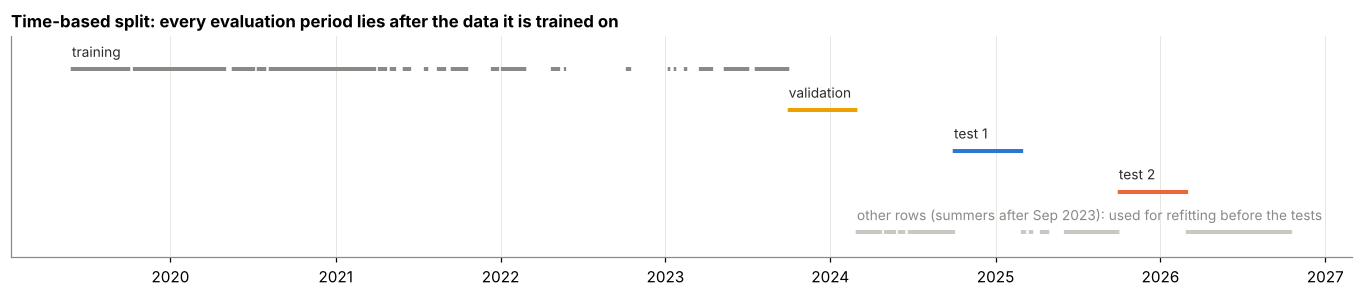

In [6]:
fig, ax = plt.subplots(figsize=(13, 2.8))
bands = [("training", train, GREY), ("validation", validation, YELLOW), ("test 1", test1, BLUE), ("test 2", test2, ORANGE)]
for i, (lab, part, col) in enumerate(bands):
    ax.scatter(part.index, np.full(len(part), 3 - i), s=6, color=col, marker="|")
    ax.text(part.index.min(), 3 - i + 0.3, lab, fontsize=9, color=DARK)
other = df[~df.index.isin(pd.concat([train, validation, test1, test2]).index)]
ax.scatter(other.index, np.full(len(other), -1), s=6, color="#c9c8c3", marker="|")
ax.text(other.index.min(), -0.7, "other rows (summers after Sep 2023): used for refitting before the tests", fontsize=9, color=GREY)
ax.set(yticks=[], ylim=(-1.6, 3.8), title="Time-based split: every evaluation period lies after the data it is trained on")
ax.grid(axis="y", visible=False); nice_dates(ax)
fig.tight_layout(); savefig(fig, "p2_01_split_timeline")

## 3.2 Two prediction targets
We try two ways of asking the model for tomorrow:
- **Level:** predict `pm25_tomorrow` directly.
- **Change:** predict the *change* `pm25_tomorrow − pm25_today`, then add today's value back.

The change target follows from the Phase-1 EDA. Persistence explains most of the level, so a model that only has to learn the *change* (what the weather and the fires will do) can focus on what persistence cannot know. Section 5 tests which works better.

The helper below fits a model on one period and predicts another, for either target. Predictions are clipped at 0, because PM2.5 cannot be negative.

In [7]:
def fit_predict(model, train_df, test_df, features=FEATURES, target="change"):
    "Fit on train_df and return the predicted PM2.5 for test_df. target = 'level' or 'change'."
    y = train_df["pm25_tomorrow"] - (train_df["pm25_today"] if target == "change" else 0)
    model.fit(train_df[features], y)
    pred = model.predict(test_df[features])
    if target == "change":
        pred = pred + test_df["pm25_today"].to_numpy()
    return np.clip(pred, 0, None)

def walk_forward(make_model, features=FEATURES, target="change"):
    "Walk-forward validation: per winter, train on everything before it. Returns pooled (y_true, y_pred, dates)."
    ys, ps, ds = [], [], []
    for y in WALK_FORWARD:
        tr, te = df[df.index < f"{y}-10-01"], df[winter(y)]
        ps.append(fit_predict(make_model(), tr, te, features, target)); ys.append(te["pm25_tomorrow"].to_numpy()); ds.append(te.index)
    return np.concatenate(ys), np.concatenate(ps), np.concatenate(ds)

def wf_mae(y, p, dates):
    "MAE per walk-forward winter and their mean."
    s = pd.Series(np.abs(y - p), index=pd.DatetimeIndex(dates))
    per = {f"WF {w}-{str(w + 1)[2:]}": s[(s.index >= f"{w}-10-01") & (s.index <= f"{w + 1}-02-28")].mean() for w in WALK_FORWARD}
    per["WF mean"] = float(np.mean(list(per.values())))
    return per
print("Training / prediction helpers ready.")

Training / prediction helpers ready.


# 4. Baselines
A model is only useful if it beats simple rules. We use two baselines:
- **Persistence:** *tomorrow = today*. This is the natural benchmark for a persistent series.
- **Climatology:** tomorrow = the average PM2.5 for that **week of the year** in the training years. This is the "typical seasonal value" a person might guess.

In [8]:
def climatology_predict(train_df, test_df):
    target_week = lambda idx: (idx + pd.Timedelta(days=1)).isocalendar().week.to_numpy()   # week of TOMORROW
    by_week = pd.Series(train_df["pm25_tomorrow"].to_numpy()).groupby(target_week(train_df.index)).mean()
    return pd.Series(target_week(test_df.index)).map(by_week).fillna(train_df["pm25_tomorrow"].mean()).to_numpy()

rows = []
for name, part, tr in [("validation 23-24", validation, train), ("test 1 (24-25)", test1, dev), ("test 2 (25-26)", test2, dev2)]:
    for base, pred in [("persistence", part["pm25_today"].to_numpy()), ("climatology", climatology_predict(tr, part))]:
        rows.append({"period": name, "baseline": base, **regression_scores(part["pm25_tomorrow"], pred),
                     **{k: v for k, v in warning_scores(part["pm25_tomorrow"], pred >= HAZARDOUS).items() if k in ("recall", "precision", "F1")}})
baselines = pd.DataFrame(rows).set_index(["period", "baseline"])
baselines.round(3)

MAE    RMSE    R2  recall  precision    F1
period           baseline                                                 
validation 23-24 persistence 47.440  65.041 0.545   0.829      0.829 0.829
                 climatology 65.118  79.881 0.313   0.474      0.735 0.576
test 1 (24-25)   persistence 52.465  78.302 0.508   0.800      0.800 0.800
                 climatology 69.826 100.112 0.196   0.545      0.536 0.541
test 2 (25-26)   persistence 33.838  43.989 0.692   0.851      0.851 0.851
                 climatology 51.351  63.372 0.361   0.821      0.724 0.769

**Discussion:**
- **Persistence is much better than climatology** in every period. Knowing today's level is worth more than knowing the season.
- Persistence makes errors of about **47–52 µg/m³ in the validation winter and test 1**, and about **34 µg/m³ in test 2**, with R² around 0.5–0.7. As a warning it already catches about **80–85 %** of hazardous days.
- This sets the bar: **a model is only worth deploying if it clearly beats persistence on MAE, without losing warning recall.**

# 5. Model selection and implementation
## 5.1 Candidate models
We compare three model families that suit a **small tabular dataset** of about 1,000–1,700 training rows with 15 features:

| Model | How it works | Why it is a candidate |
|---|---|---|
| **Ridge regression** (with standardisation) | A linear model with an L2 penalty that shrinks the coefficients | Simple, fast and interpretable; a strong check of whether non-linear models are needed. Standardisation puts features with different units on one scale. |
| **Random Forest** | Averages hundreds of decision trees, each trained on a bootstrap sample with random feature subsets | Captures non-linear effects (e.g. rain only matters above a few mm) and interactions; robust and hard to overfit |
| **Histogram Gradient Boosting** (scikit-learn's LightGBM-style booster) | Builds trees one after another, each correcting the errors of the previous ones | Often the most accurate model on tabular data; handles skewed features without transforms |

Deep learning (LSTMs) is **not** a good fit here: with fewer than 2,000 rows it would overfit, and the EDA showed the signal is mostly captured by a few lagged values and weather features, which the trees use directly.

## 5.2 First comparison with default settings
Each model is trained with reasonable default settings, for **both targets**, and evaluated with **walk-forward validation** over three winters. Here and later, "WF mean" is the average MAE over the three validation winters.

In [9]:
def make_ridge(alpha=1.0):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))
def make_rf(**kw):
    p = dict(n_estimators=300, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=SEED); p.update(kw)
    return RandomForestRegressor(**p)
def make_hgb(**kw):
    p = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20, random_state=SEED); p.update(kw)
    return HistGradientBoostingRegressor(**p)

DEFAULT_MODELS = {"Ridge": make_ridge, "Random Forest": make_rf, "Gradient Boosting": make_hgb}
t0 = time.time()
rows = []
# persistence on the same walk-forward winters, for reference
yy, pp, dd = [], [], []
for y in WALK_FORWARD:
    te = df[winter(y)]; yy.append(te.pm25_tomorrow.to_numpy()); pp.append(te.pm25_today.to_numpy()); dd.append(te.index)
rows.append({"model": "Persistence (baseline)", "target": "-", **wf_mae(np.concatenate(yy), np.concatenate(pp), np.concatenate(dd))})
for name, make in DEFAULT_MODELS.items():
    for target in ["level", "change"]:
        y, p, d = walk_forward(make, target=target)
        rows.append({"model": name, "target": target, **wf_mae(y, p, d)})
default_cmp = pd.DataFrame(rows).set_index(["model", "target"])
print(f"({time.time() - t0:.0f} s)")
default_cmp.round(2)

(5 s)


WF 2020-21  WF 2021-22  WF 2023-24  WF mean
model                  target                                             
Persistence (baseline) -           52.690      47.890      47.440   49.340
Ridge                  level       47.660      42.470      40.300   43.480
                       change      47.510      42.510      40.290   43.440
Random Forest          level       43.070      44.560      38.490   42.040
                       change      45.600      44.820      39.780   43.400
Gradient Boosting      level       48.240      43.020      44.010   45.090
                       change      46.640      46.790      42.780   45.400

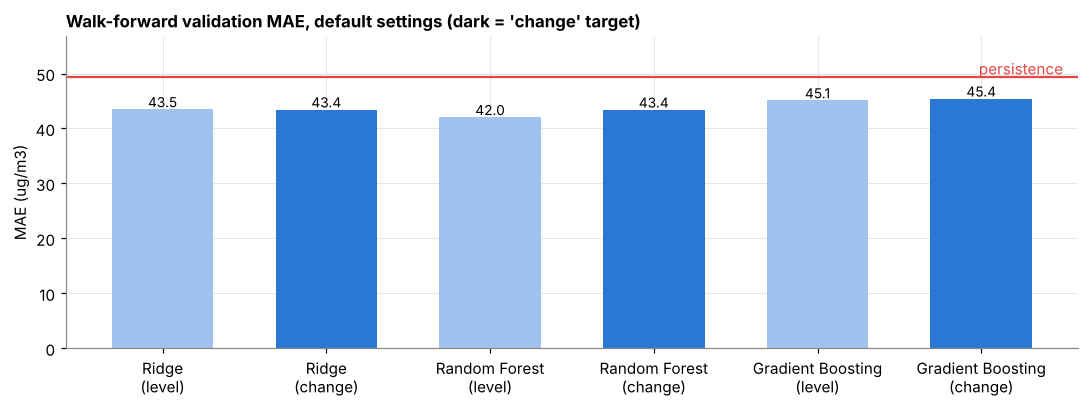

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8))
plot = default_cmp["WF mean"].drop(("Persistence (baseline)", "-"))
labels = [f"{m}\n({t})" for m, t in plot.index]
cols = [BLUE if t == "change" else "#9fc3ee" for _, t in plot.index]
bars = ax.bar(labels, plot.values, color=cols, width=0.62)
ax.axhline(default_cmp.loc[("Persistence (baseline)", "-"), "WF mean"], color=RED, lw=1.5)
ax.text(len(plot) - 0.5, default_cmp.loc[("Persistence (baseline)", "-"), "WF mean"] + 0.5, "persistence", color=RED, ha="right")
for b, v in zip(bars, plot.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f"{v:.1f}", ha="center", fontsize=9)
ax.set(title="Walk-forward validation MAE, default settings (dark = 'change' target)", ylabel="MAE (ug/m3)",
       ylim=(0, default_cmp["WF mean"].max() * 1.15))
fig.tight_layout(); savefig(fig, "p2_02_default_models")

**Discussion:**
- **Every model beats persistence**, even with default settings, so the features carry useful information beyond today's value.
- **Ridge is surprisingly strong.** Much of the relationship is close to linear: tomorrow ≈ today, adjusted by the weather.
- **Default Gradient Boosting is the weakest** of the three. With these settings it overfits the small dataset, which is a clear case for tuning (Section 6).
- **Level or change?** The average MAE does not give a clear winner. For Ridge the two targets are practically identical, because today's value is already a linear input. Both tree models are **slightly better with "level" on average** (Random Forest by about 1.4 µg/m³, Gradient Boosting by about 0.3). Before deciding, we look at the days that matter most: the most polluted ones.

In [11]:
rows = []
for name, make in [("Random Forest", make_rf), ("Gradient Boosting", make_hgb)]:
    for target in ["level", "change"]:
        y, p, d = walk_forward(make, target=target)
        top = y >= np.percentile(y, 90)
        rows.append({"model": name, "target": target, "MAE all days": np.abs(y - p).mean(),
                     "MAE on the 10 % worst days": np.abs(y - p)[top].mean(), "highest forecast": p.max()})
extremes = pd.DataFrame(rows).set_index(["model", "target"])
print(f"Highest PM2.5 in the walk-forward winters: {y.max():.0f} ug/m3 | in the training data before test 1: "
      f"{dev.pm25_tomorrow.max():.0f} | in test 1: {test1.pm25_tomorrow.max():.0f} ug/m3")
extremes.round(1)

Highest PM2.5 in the walk-forward winters: 510 ug/m3 | in the training data before test 1: 510 | in test 1: 630 ug/m3


MAE all days  MAE on the 10 % worst days  highest forecast
model             target                                                            
Random Forest     level         41.500                      94.600           386.500
                  change        43.000                      91.000           447.300
Gradient Boosting level         45.400                      80.200           419.800
                  change        45.100                      76.400           471.900

**Decision: the "change" target, for all models.**
- On the **10 % most polluted days**, the change target is better for *both* tree models. These are the days that decide the hazardous warning.
- A tree that predicts the **level** can never forecast more than the highest value in its training data: each leaf is an average of training targets. In the walk-forward runs, the level-target forest never predicts above about 390 µg/m³. A model that predicts the **change** adds it to today's value, so it can follow a record-breaking episode. This matters in practice: **test 1 contains a day of 630 µg/m³, far above anything in the training data (510)**.
- The price is about 1.4 µg/m³ of average MAE for Random Forest (0.3 for Gradient Boosting) on the validation winters. We accept it in exchange for better behaviour on extreme days and a model that can handle new records. Section 9 shows the test results for both targets, so this choice can be checked.

# 6. Hyperparameter tuning
We tune each model with **`RandomizedSearchCV`** on the **training period only** (May 2019 – Sep 2023), using **`TimeSeriesSplit(n_splits=5)`** as the cross-validation scheme. Each fold trains on an earlier stretch and validates on the stretch right after it, so no fold ever looks into the future. The validation winter and both test winters are not used here.

Randomised search tries random combinations from a distribution for each hyperparameter. With a fixed budget it usually finds good settings faster than a full grid search.

| Model | Hyperparameters searched |
|---|---|
| Ridge | `alpha`: penalty strength, 0.01–1,000 (log scale) |
| Random Forest | number of trees, `max_depth`, `min_samples_leaf` (leaf size), `max_features` (share of features per split) |
| Gradient Boosting | `learning_rate`, `max_iter` (number of trees), `max_leaf_nodes` (tree size), `min_samples_leaf`, `l2_regularization` |

In [12]:
y_train_change = train["pm25_tomorrow"] - train["pm25_today"]
cv = TimeSeriesSplit(n_splits=5)
searches = {
    "Ridge": (make_ridge(), {"ridge__alpha": loguniform(1e-2, 1e3)}, 25),
    "Random Forest": (make_rf(), {"n_estimators": [200, 300, 500], "max_depth": [None, 6, 10, 16],
                                  "min_samples_leaf": randint(1, 15), "max_features": uniform(0.2, 0.8)}, 15),
    "Gradient Boosting": (make_hgb(), {"learning_rate": loguniform(0.01, 0.2), "max_iter": randint(100, 600),
                                       "max_leaf_nodes": randint(4, 32), "min_samples_leaf": randint(10, 80),
                                       "l2_regularization": loguniform(1e-3, 10)}, 40),
}
from sklearn.base import clone
tuned, BEST, tuning_rows = {}, {}, []
for name, (est, space, n_iter) in searches.items():
    t0 = time.time()
    rs = RandomizedSearchCV(est, space, n_iter=n_iter, cv=cv, scoring="neg_mean_absolute_error",
                            random_state=SEED, n_jobs=-1).fit(train[FEATURES], y_train_change)
    tuned[name] = rs
    default_cv = np.mean([mean_absolute_error(y_train_change.iloc[te], clone(est).fit(train[FEATURES].iloc[tr], y_train_change.iloc[tr])
                                              .predict(train[FEATURES].iloc[te])) for tr, te in cv.split(train)])
    use_tuned = -rs.best_score_ < default_cv                     # keep the default if the search did not beat it
    BEST[name] = rs.best_estimator_ if use_tuned else est
    best = {k.replace("ridge__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in rs.best_params_.items()}
    tuning_rows.append({"model": name, "combinations tried": n_iter, "CV MAE default": default_cv,
                        "CV MAE best found": -rs.best_score_, "used": "tuned" if use_tuned else "default",
                        "best settings found": best, "seconds": round(time.time() - t0)})
tuning = pd.DataFrame(tuning_rows).set_index("model")
tuning

,combinations tried,CV MAE default,CV MAE best found,used,best settings found,seconds
model,,,,,,
Ridge,25,33.256,30.016,tuned,{'alpha': 145.2825},2
Random Forest,15,29.770,29.808,default,"{'max_depth': 16, 'max_features': 0.5961, 'min...",24
Gradient Boosting,40,32.967,29.821,tuned,"{'l2_regularization': 0.0071, 'learning_rate':...",22


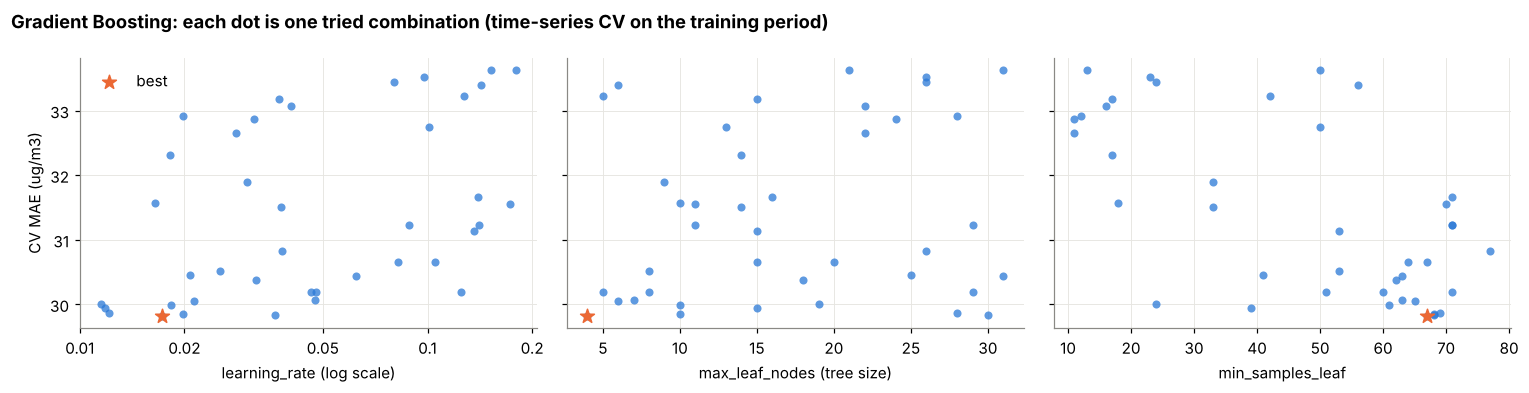

In [13]:
cvres = pd.DataFrame(tuned["Gradient Boosting"].cv_results_)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, p, lab, logx in [(axes[0], "param_learning_rate", "learning_rate (log scale)", True),
                         (axes[1], "param_max_leaf_nodes", "max_leaf_nodes (tree size)", False),
                         (axes[2], "param_min_samples_leaf", "min_samples_leaf", False)]:
    ax.scatter(cvres[p].astype(float), -cvres["mean_test_score"], s=28, color=BLUE, alpha=0.75, linewidths=0)
    best = cvres.loc[cvres["rank_test_score"] == 1]
    ax.scatter(best[p].astype(float), -best["mean_test_score"], s=90, color=ORANGE, marker="*", label="best")
    ax.set(xlabel=lab, xscale="log" if logx else "linear")
    if logx:
        ax.set_xticks([0.01, 0.02, 0.05, 0.1, 0.2], ["0.01", "0.02", "0.05", "0.1", "0.2"]); ax.minorticks_off()
axes[0].set_ylabel("CV MAE (ug/m3)"); axes[0].legend(loc="upper left")
fig.suptitle("Gradient Boosting: each dot is one tried combination (time-series CV on the training period)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); savefig(fig, "p2_03_hgb_tuning")

**Discussion:**
- **Gradient Boosting gains the most from tuning** (CV MAE from about 33 to about 30). Its best settings are a **small learning rate, very small trees and large leaves**, i.e. a strongly *regularised* booster. This fits a small, noisy dataset: the default settings were too flexible.
- **Ridge also improves clearly** with a much stronger penalty (`alpha` ≈ 145 instead of 1). The strong penalty keeps the coefficients of the correlated weather features stable.
- **Random Forest does not improve:** the best random combination is no better than our default settings, so **we keep the defaults** (the `used` column). This is common: random forests are known to be robust to their hyperparameters. Note that the code always keeps whichever version has the lower CV error.
- The scatter shows that high learning rates and very small `min_samples_leaf` values do worst for Gradient Boosting. The good region is broad, so the result is not a lucky single point.
- *Note:* the CV folds here are mixed seasons, so the MAE values are lower than the winter-only numbers elsewhere. Only the comparison within this table matters.

# 7. Optimisation and performance improvement
Starting from the tuned models, we test three further ideas on the walk-forward validation winters:
1. **Ensemble:** average the predictions of the three tuned models (scikit-learn `VotingRegressor`). Models that make *different* mistakes partly cancel each other out.
2. **Smog-season weighting:** give winter rows twice the weight in training, because winters are what we are evaluated on.
3. **Fewer features:** drop the fire features. The full test of this is the research question in Section 11; here it is only a quick check.

In [14]:
def clone_best(name):
    "A fresh, unfitted copy of the chosen (tuned or default) model."
    return clone(BEST[name])

def make_ensemble():
    return VotingRegressor([("ridge", clone_best("Ridge")), ("rf", clone_best("Random Forest")),
                            ("hgb", clone_best("Gradient Boosting"))])

class WeightedEnsemble:
    "The same three-model average, but smog-season rows get weight w during training."
    def __init__(self, w=2.0): self.w = w
    def fit(self, X, y):
        sw = np.where(X["smog_season"] == 1, self.w, 1.0)
        self.models = [clone_best("Ridge").fit(X, y, ridge__sample_weight=sw),
                       clone_best("Random Forest").fit(X, y, sample_weight=sw),
                       clone_best("Gradient Boosting").fit(X, y, sample_weight=sw)]
        return self
    def predict(self, X): return np.mean([m.predict(X) for m in self.models], axis=0)

t0 = time.time()
candidates = {
    "Ridge (tuned)":             (lambda: clone_best("Ridge"), FEATURES),
    "Random Forest":             (lambda: clone_best("Random Forest"), FEATURES),
    "Gradient Boosting (tuned)": (lambda: clone_best("Gradient Boosting"), FEATURES),
    "Ensemble of the three":     (make_ensemble, FEATURES),
    "Ensemble, winter weight x2": (lambda: WeightedEnsemble(2.0), FEATURES),
    "Ensemble without fire features": (make_ensemble, NO_FIRE),
}
wf_pred, rows = {}, []
for name, (make, feats) in candidates.items():
    y, p, d = walk_forward(make, features=feats)
    wf_pred[name] = p
    rows.append({"model": name, **wf_mae(y, p, d), **{k: v for k, v in regression_scores(y, p).items() if k != "MAE"}})
WF_Y, WF_DATES = y, d
optim = pd.DataFrame(rows).set_index("model")
print(f"({time.time() - t0:.0f} s)")
optim.round(2)

(10 s)


,WF 2020-21,WF 2021-22,WF 2023-24,WF mean,RMSE,R2
model,,,,,,
Ridge (tuned),46.510,43.690,41.210,43.800,58.800,0.640
Random Forest,45.600,44.820,39.780,43.400,56.890,0.660
Gradient Boosting (tuned),45.930,44.300,42.530,44.250,59.760,0.630
Ensemble of the three,44.990,43.240,40.280,42.840,56.880,0.660
"Ensemble, winter weight x2",44.920,42.930,40.150,42.660,56.550,0.670
Ensemble without fire features,45.080,43.070,40.310,42.820,56.520,0.670


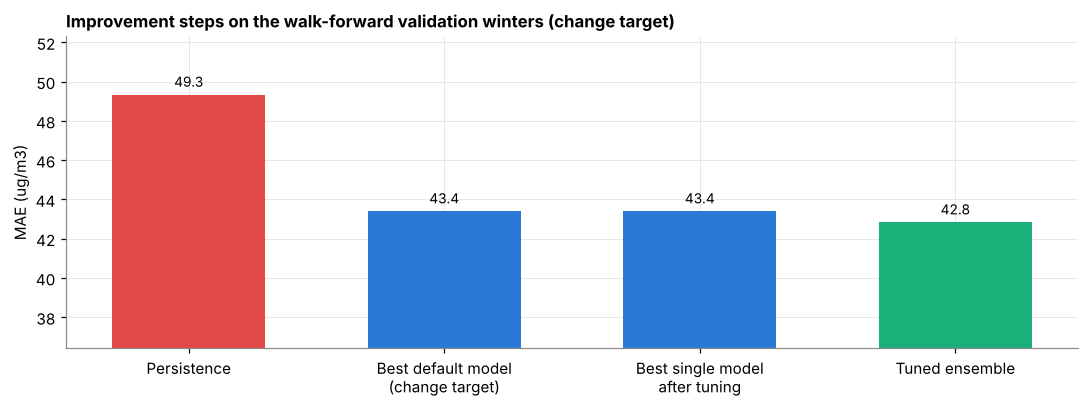

Total improvement over persistence on validation: 13.2 %


In [15]:
steps = [("Persistence", default_cmp.loc[("Persistence (baseline)", "-"), "WF mean"]),
         ("Best default model\n(change target)", default_cmp.xs("change", level="target")["WF mean"].min()),
         ("Best single model\nafter tuning", optim.loc[["Ridge (tuned)", "Random Forest", "Gradient Boosting (tuned)"], "WF mean"].min()),
         ("Tuned ensemble", optim.loc["Ensemble of the three", "WF mean"])]
fig, ax = plt.subplots(figsize=(10, 3.8))
vals = [v for _, v in steps]
bars = ax.bar([s for s, _ in steps], vals, color=[RED] + [BLUE] * 2 + [AQUA], width=0.6)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f"{v:.1f}", ha="center", fontsize=9)
ax.set(title="Improvement steps on the walk-forward validation winters (change target)", ylabel="MAE (ug/m3)", ylim=(min(vals) * 0.85, max(vals) * 1.06))
fig.tight_layout(); savefig(fig, "p2_04_improvement_steps")
print(f"Total improvement over persistence on validation: {100 * (1 - vals[-1] / vals[0]):.1f} %")

**Discussion:**
- **The ensemble is the best of the change-target models on validation.** Its walk-forward mean is about 0.6 µg/m³ lower than the best single model (Random Forest). The three models make partly different errors (linear vs tree-based), and averaging them cancels part of these errors.
- **Winter weighting is marginally better** (by about 0.2 µg/m³, or 0.4 %). That is far less than the variation between winters, so **we treat differences below about 0.5 µg/m³ as ties and keep the simpler model**, without sample weights. The models already learn winter behaviour from the `smog_season`, `month` and weather inputs.
- **Without the fire features the validation MAE is practically the same.** So on these three winters, fires add almost nothing on average. Section 11 looks at this properly, including the burning season and the test winters.
- **Note how noisy a single validation winter is.** The ranking of models changes from one winter to the next, which is why we choose by the **mean over three winters**, not by one.

### Model selection
**Selected model: the ensemble (tuned Ridge + Random Forest + tuned Gradient Boosting, change target, all 15 features).** It has the lowest walk-forward validation MAE among the change-target models (42.8 vs 49.3 for persistence, **13 % better**).

For full transparency: the *level-target* Random Forest from Section 5 had a slightly lower average validation MAE (42.0). We set it aside because it is weaker on the most polluted days and cannot forecast new record values. The test winters have not been looked at yet; Section 9 will show whether these choices hold up.

# 8. From forecast to warning and AQI category
The regression forecast also answers the two classification tasks:
- **AQI category:** apply the EPA breakpoints to the forecast value.
- **Hazardous warning:** warn when the forecast is above a **warning threshold τ**.

Choosing τ = 225.5 (the hazardous level itself) is not necessarily best. A forecast just below the line, e.g. 215, still means a high chance of a hazardous day. We choose τ on the **validation predictions** with a public-health rule: **the highest τ that still catches at least 85 % of hazardous days (recall ≥ 0.85)**, so that warnings stay reliable without crying wolf too often.

We also compare with a **dedicated classifier**: a Gradient Boosting *classifier* trained directly on `hazardous_tomorrow`, with class weights balanced for the minority class and the same recall rule for its probability threshold.

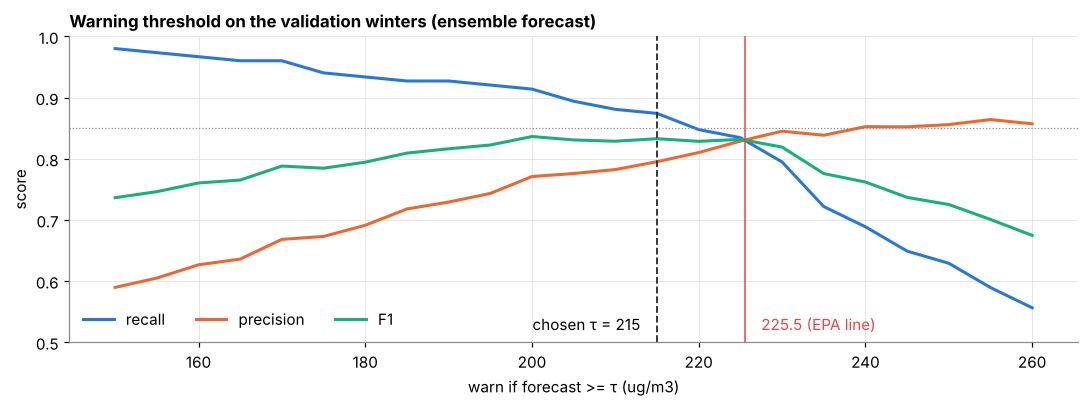

Chosen warning threshold τ = 215 ug/m3 -> {'recall': 0.874, 'precision': 0.795, 'F1': 0.833}
At τ = 225.5 instead       -> {'recall': 0.834, 'precision': 0.829, 'F1': 0.832}


In [16]:
ens_val = wf_pred["Ensemble of the three"]
hz_val = WF_Y >= HAZARDOUS
thr_grid = np.arange(150, 261, 5)
curve = pd.DataFrame([{"threshold": t, **{k: v for k, v in warning_scores(WF_Y, ens_val >= t).items() if k in ("recall", "precision", "F1")}}
                      for t in thr_grid]).set_index("threshold")
TAU = float(curve[curve.recall >= 0.85].index.max())

fig, ax = plt.subplots(figsize=(10, 3.8))
for col, c in [("recall", BLUE), ("precision", ORANGE), ("F1", AQUA)]:
    ax.plot(curve.index, curve[col], color=c, lw=2, label=col)
ax.axvline(TAU, color=DARK, lw=1.2, ls="--"); ax.text(TAU - 2, 0.52, f"chosen τ = {TAU:.0f}", ha="right")
ax.axvline(HAZARDOUS, color=RED, lw=1); ax.text(HAZARDOUS + 2, 0.52, "225.5 (EPA line)", color=RED)
ax.axhline(0.85, color=GREY, lw=0.8, ls=":")
ax.set(title="Warning threshold on the validation winters (ensemble forecast)", xlabel="warn if forecast >= τ (ug/m3)",
       ylabel="score", ylim=(0.5, 1.0))
ax.legend(loc="lower left", ncol=3)
fig.tight_layout(); savefig(fig, "p2_05_threshold")
print(f"Chosen warning threshold τ = {TAU:.0f} ug/m3 ->", {k: round(v, 3) for k, v in curve.loc[TAU].items()})
print(f"At τ = 225.5 instead       ->", {k: round(v, 3) for k, v in
      warning_scores(WF_Y, ens_val >= HAZARDOUS).items() if k in ("recall", "precision", "F1")})

In [17]:
def make_hz_classifier():
    return HistGradientBoostingClassifier(learning_rate=0.03, max_iter=300, max_leaf_nodes=9, min_samples_leaf=40,
                                          class_weight="balanced", random_state=SEED)
probs = []
for y in WALK_FORWARD:
    tr, te = df[df.index < f"{y}-10-01"], df[winter(y)]
    probs.append(make_hz_classifier().fit(tr[FEATURES], tr["hazardous_tomorrow"]).predict_proba(te[FEATURES])[:, 1])
clf_val = np.concatenate(probs)
p_grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
clf_curve = pd.DataFrame([{"p": p, **{k: v for k, v in warning_scores(WF_Y, clf_val >= p).items() if k in ("recall", "precision", "F1")}}
                          for p in p_grid]).set_index("p")
P_CLF = float(clf_curve[clf_curve.recall >= 0.85].index.max())

def make_cat_classifier():
    return HistGradientBoostingClassifier(learning_rate=0.03, max_iter=300, max_leaf_nodes=9, min_samples_leaf=30,
                                          class_weight="balanced", random_state=SEED)
cats = []
for y in WALK_FORWARD:
    tr, te = df[df.index < f"{y}-10-01"], df[winter(y)]
    cats.append(make_cat_classifier().fit(tr[FEATURES], to_category(tr["pm25_tomorrow"])).predict(te[FEATURES]))
cat_clf_val = np.concatenate(cats)

hz_cmp = pd.DataFrame({
    "Persistence (today >= 225.5)": warning_scores(WF_Y, np.concatenate([df[winter(y)].pm25_today for y in WALK_FORWARD]) >= HAZARDOUS),
    f"Ensemble forecast >= τ ({TAU:.0f})": warning_scores(WF_Y, ens_val >= TAU),
    f"Direct classifier (p >= {P_CLF:.2f})": warning_scores(WF_Y, clf_val >= P_CLF)}).T
hz_cmp["PR-AUC"] = [np.nan, average_precision_score(hz_val, ens_val), average_precision_score(hz_val, clf_val)]
cat_cmp = pd.DataFrame({
    "Persistence (today's category)": category_scores(WF_Y, to_category(np.concatenate([df[winter(y)].pm25_today for y in WALK_FORWARD]))),
    "Category of the ensemble forecast": category_scores(WF_Y, to_category(ens_val)),
    "Direct multi-class classifier": category_scores(WF_Y, cat_clf_val)}).T
print("Hazardous warning - validation winters:"); display(hz_cmp.round(3))
print("AQI category - validation winters:");     display(cat_cmp.round(3))

Hazardous warning - validation winters:


,recall,precision,F1,warnings,hazardous days,PR-AUC
Persistence (today >= 225.5),0.788,0.788,0.788,151.000,151.000,NaN
Ensemble forecast >= τ (215),0.874,0.795,0.833,166.000,151.000,0.874
Direct classifier (p >= 0.70),0.854,0.746,0.796,173.000,151.000,0.808


AQI category - validation winters:


,accuracy,macro-F1,within one category
Persistence (today's category),0.664,0.458,0.981
Category of the ensemble forecast,0.733,0.514,0.986
Direct multi-class classifier,0.681,0.446,0.983


**Discussion:**
- **The warning rule.** The chosen threshold sits **below** 225.5. Warning a little earlier raises recall to the 85 % target while keeping precision reasonable. The curve shows the usual trade-off: lowering τ catches more hazardous days but raises more false alarms.
- **Forecast-based warning vs dedicated classifier.** The warning derived from the regression forecast is **at least as good as the dedicated classifier** (higher PR-AUC), even though the classifier was trained only for this task. The regression model learns from the *exact* PM2.5 values, while the classifier only sees "above or below 225.5" and throws that information away.
- **AQI category.** Again, **the category of the forecast beats the direct multi-class classifier** and persistence. Almost all predictions are within one category of the truth.

**Decision:** one regression ensemble serves all three tasks: the PM2.5 value, its category, and a warning at threshold τ. This is simpler to maintain and also more accurate.

# 9. Final evaluation on the test winters
All choices are now fixed: the model (the ensemble), the target ("change"), the hyperparameters, and the warning threshold τ. Each model is **refitted on all data available before its test winter** and evaluated **once**:
- **Test 1, winter 2024–25:** trained on everything before Oct 2024. Its targets are mostly from the US reference monitor.
- **Test 2, winter 2025–26:** trained on everything before Oct 2025. Its targets come from the **calibrated low-cost sensors**, so this also tests whether the Phase-1 calibration transfers.

All models from the comparison are shown, so the final choice can be checked against the alternatives.

In [18]:
TESTS = {"test 1 (24-25)": (dev, test1), "test 2 (25-26)": (dev2, test2)}
MODELS_FINAL = {
    "Ridge (tuned)":             (lambda: clone_best("Ridge"), "change"),
    "Random Forest (level target)": (lambda: clone_best("Random Forest"), "level"),
    "Random Forest":             (lambda: clone_best("Random Forest"), "change"),
    "Gradient Boosting (tuned)": (lambda: clone_best("Gradient Boosting"), "change"),
    "Ensemble (selected)":       (make_ensemble, "change"),
}
t0 = time.time()
test_pred, rows = {}, []
for tname, (tr, te) in TESTS.items():
    preds = {"Persistence": te["pm25_today"].to_numpy(), "Climatology": climatology_predict(tr, te)}
    for mname, (make, target) in MODELS_FINAL.items():
        preds[mname] = fit_predict(make(), tr, te, FEATURES, target)
    test_pred[tname] = preds
    base_mae = mean_absolute_error(te["pm25_tomorrow"], preds["Persistence"])
    for mname, p in preds.items():
        warn_thr = TAU if mname not in ("Persistence", "Climatology") else HAZARDOUS
        w = warning_scores(te["pm25_tomorrow"], p >= warn_thr)
        rows.append({"test": tname, "model": mname, **regression_scores(te["pm25_tomorrow"], p),
                     "warn recall": w["recall"], "warn precision": w["precision"], "warn F1": w["F1"],
                     **{f"AQI {k}": v for k, v in category_scores(te["pm25_tomorrow"], to_category(p)).items()},
                     "MAE vs persistence %": 100 * (1 - mean_absolute_error(te["pm25_tomorrow"], p) / base_mae)})
results = pd.DataFrame(rows).set_index(["test", "model"])
results.to_csv(RESULTS_DIR / "test_results.csv")
print(f"({time.time() - t0:.0f} s)  saved to {os.path.relpath(RESULTS_DIR / 'test_results.csv')}")
results.round(3)

(5 s)  saved to results/test_results.csv


MAE    RMSE    R2  warn recall  warn precision  warn F1  AQI accuracy  AQI macro-F1  AQI within one category  \
test           model                                                                                                                                          
test 1 (24-25) Persistence                  52.465  78.302 0.508        0.800           0.800    0.800         0.735         0.546                    0.993   
               Climatology                  69.826 100.112 0.196        0.545           0.536    0.541         0.517         0.400                    0.986   
               Ridge (tuned)                45.725  70.272 0.604        0.873           0.750    0.807         0.741         0.556                    1.000   
               Random Forest (level target) 49.841  72.320 0.581        0.891           0.731    0.803         0.748         0.555                    1.000   
               Random Forest                45.102  66.849 0.642        0.927           0.761    0.836         0.755         0.562                    1.000   
               Gradient Boosting (tuned)    44.911  67.647 0.633        0.909           0.735    0.813         0.769         0.567                    1.000   
               Ensemble (selected)          44.321  67.336 0.636        0.909           0.746    0.820         0.769         0.570                    1.000   
test 2 (25-26) Persistence                  33.838  43.989 0.692        0.851           0.851    0.851         0.747         0.424                    0.987   
               Climatology                  51.351  63.372 0.361        0.821           0.724    0.769         0.607         0.327                    0.973   
               Ridge (tuned)                28.576  37.921 0.771        0.925           0.861    0.892         0.793         0.449                    0.987   
               Random Forest (level target) 28.333  36.876 0.784        0.955           0.800    0.871         0.793         0.451                    0.993   
               Random Forest                27.281  34.943 0.806        0.970           0.844    0.903         0.813         0.606                    1.000   
               Gradient Boosting (tuned)    27.316  35.758 0.797        0.955           0.800    0.871         0.813         0.465                    0.993   
               Ensemble (selected)          26.937  34.531 0.810        0.955           0.842    0.895         0.820         0.601                    0.993   

                                             MAE vs persistence %  
test           model                                               
test 1 (24-25) Persistence                                  0.000  
               Climatology                                -33.089  
               Ridge (tuned)                               12.847  
               Random Forest (level target)                 5.002  
               Random Forest                               14.034  
               Gradient Boosting (tuned)                   14.399  
               Ensemble (selected)                         15.523  
test 2 (25-26) Persistence                                  0.000  
               Climatology                                -51.756  
               Ridge (tuned)                               15.549  
               Random Forest (level target)                16.270  
               Random Forest                               19.378  
               Gradient Boosting (tuned)                   19.275  
               Ensemble (selected)                         20.394

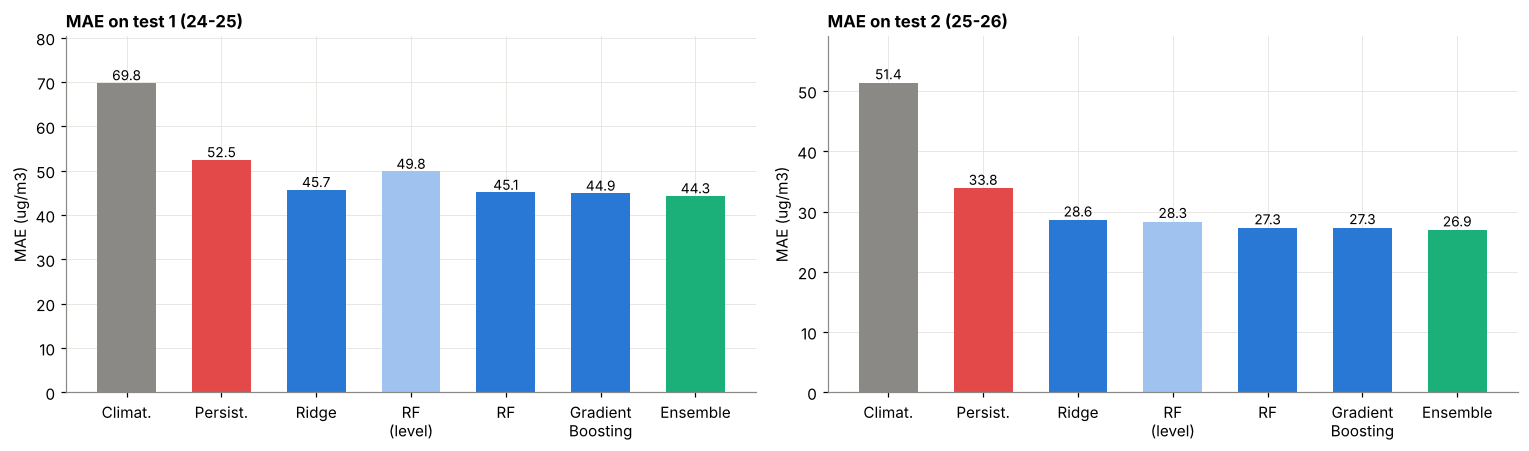

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=False)
order = ["Climatology", "Persistence", "Ridge (tuned)", "Random Forest (level target)", "Random Forest", "Gradient Boosting (tuned)", "Ensemble (selected)"]
short = ["Climat.", "Persist.", "Ridge", "RF\n(level)", "RF", "Gradient\nBoosting", "Ensemble"]
for ax, tname in zip(axes, TESTS):
    v = results.loc[tname].loc[order, "MAE"]
    cols = [GREY, RED, BLUE, "#9fc3ee", BLUE, BLUE, AQUA]
    bars = ax.bar(short, v.values, color=cols, width=0.62)
    for b, val in zip(bars, v.values):
        ax.text(b.get_x() + b.get_width() / 2, val + 0.6, f"{val:.1f}", ha="center", fontsize=9)
    ax.set(title=f"MAE on {tname}", ylabel="MAE (ug/m3)", ylim=(0, v.max() * 1.15))
fig.tight_layout(); savefig(fig, "p2_06_test_mae")

**Discussion of the test results:**
- **The selected ensemble has the lowest MAE on both test winters.** It cuts the MAE of persistence by **15.5 % (test 1: 52.5 → 44.3 µg/m³)** and **20.4 % (test 2: 33.8 → 26.9 µg/m³)**. R² rises from 0.51 to 0.64 in test 1, and from 0.69 to 0.81 in test 2. The single models are close behind (Gradient Boosting 44.9 and Random Forest 45.1 in test 1), so the ensemble's advantage is real but modest.
- **The target decision is confirmed.** The level-target Random Forest, which looked slightly better on validation, is the **worst model in test 1** (49.8, only 5 % better than persistence). Test 1 contains record values up to 630 µg/m³, which a level-target forest cannot predict. This is exactly the risk identified in Section 5.
- **Climatology is far behind**, which confirms that day-to-day information matters much more than the season alone.
- **Test 2 has lower errors than test 1** for every model, persistence included. Winter 2025–26 had fewer extreme spikes, which makes it an easier winter, not a better model. The fair comparison is always against persistence *within* the same winter.
- **The warning (τ = 215) catches 91 % (test 1) and 96 % (test 2) of hazardous days**, against 80–85 % for persistence. Its precision is 75 % and 84 %, so roughly 1 in 4–6 warnings is a false alarm. **AQI-category accuracy** rises from 73–75 % (persistence) to 77–82 %.

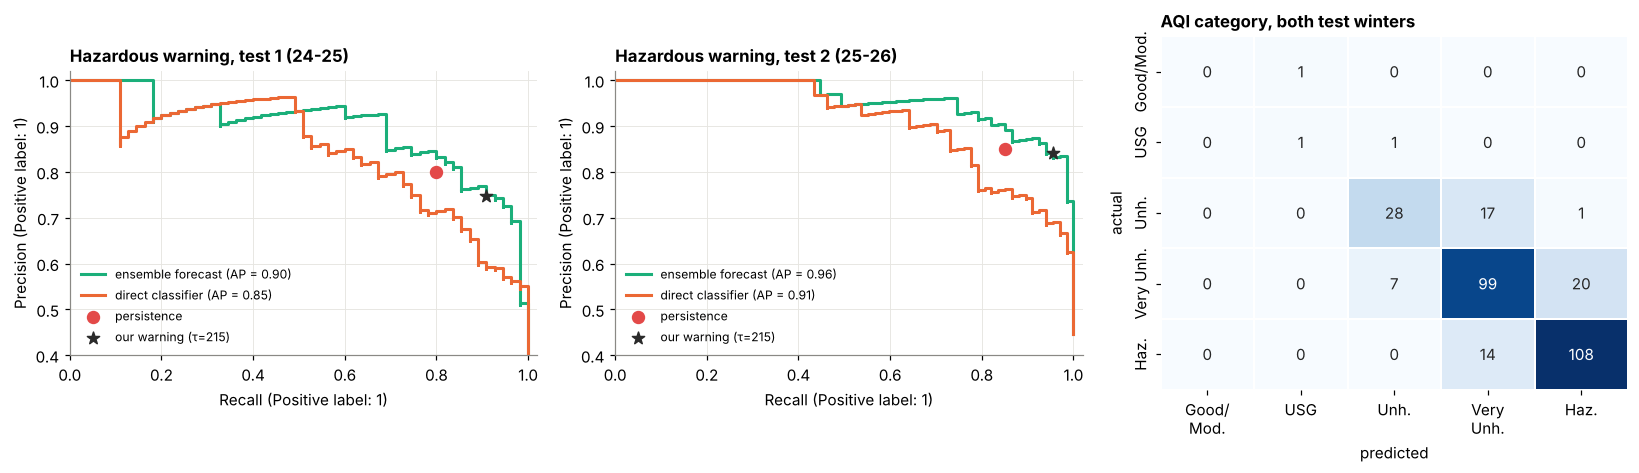

In [20]:
from sklearn.metrics import PrecisionRecallDisplay
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, tname in zip(axes[:2], TESTS):
    tr, te = TESTS[tname]
    hz = te["hazardous_tomorrow"].to_numpy()
    p_clf = make_hz_classifier().fit(tr[FEATURES], tr["hazardous_tomorrow"]).predict_proba(te[FEATURES])[:, 1]
    PrecisionRecallDisplay.from_predictions(hz, test_pred[tname]["Ensemble (selected)"], ax=ax, color=AQUA, lw=2,
                                            name="ensemble forecast")
    PrecisionRecallDisplay.from_predictions(hz, p_clf, ax=ax, color=ORANGE, lw=2,
                                            name="direct classifier")
    w = warning_scores(te["pm25_tomorrow"], te["pm25_today"] >= HAZARDOUS)
    ax.scatter([w["recall"]], [w["precision"]], color=RED, s=60, zorder=5, label="persistence")
    w = warning_scores(te["pm25_tomorrow"], test_pred[tname]["Ensemble (selected)"] >= TAU)
    ax.scatter([w["recall"]], [w["precision"]], color=DARK, s=70, marker="*", zorder=5, label=f"our warning (τ={TAU:.0f})")
    ax.set(title=f"Hazardous warning, {tname}", xlim=(0, 1.02), ylim=(0.4, 1.02))
    ax.legend(loc="lower left", fontsize=8)

both_true = np.concatenate([TESTS[t][1]["pm25_tomorrow"].to_numpy() for t in TESTS])
both_pred = np.concatenate([test_pred[t]["Ensemble (selected)"] for t in TESTS])
cm = confusion_matrix(to_category(both_true), to_category(both_pred), labels=range(5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2], linewidths=1, linecolor="white",
            xticklabels=["Good/\nMod.", "USG", "Unh.", "Very\nUnh.", "Haz."], yticklabels=["Good/Mod.", "USG", "Unh.", "Very Unh.", "Haz."])
axes[2].set(title="AQI category, both test winters", xlabel="predicted", ylabel="actual"); axes[2].grid(False)
fig.tight_layout(); savefig(fig, "p2_07_warning_and_category")

**Discussion:**
- **Precision-recall curves.** At the high recall levels a warning system needs, the curve of the **ensemble forecast** (used as a warning score) lies above the dedicated classifier. Its average precision (AP) is higher on both tests (0.90 vs 0.85, and 0.96 vs 0.91), which confirms the validation finding of Section 8. Our chosen operating point (★) lies **to the right of persistence (●)**: more hazardous days caught. Precision is a little lower in test 1 and about the same in test 2.
- **Confusion matrix.** Almost all mistakes are **one category off**, mostly between *Very Unhealthy* and *Hazardous*, which are neighbours around a hard line at 225.5. Only 1 of the 297 test days is two categories off, and a clean day is never confused with a hazardous one.

# 10. Results visualisation and error analysis
## 10.1 Forecast vs reality, day by day

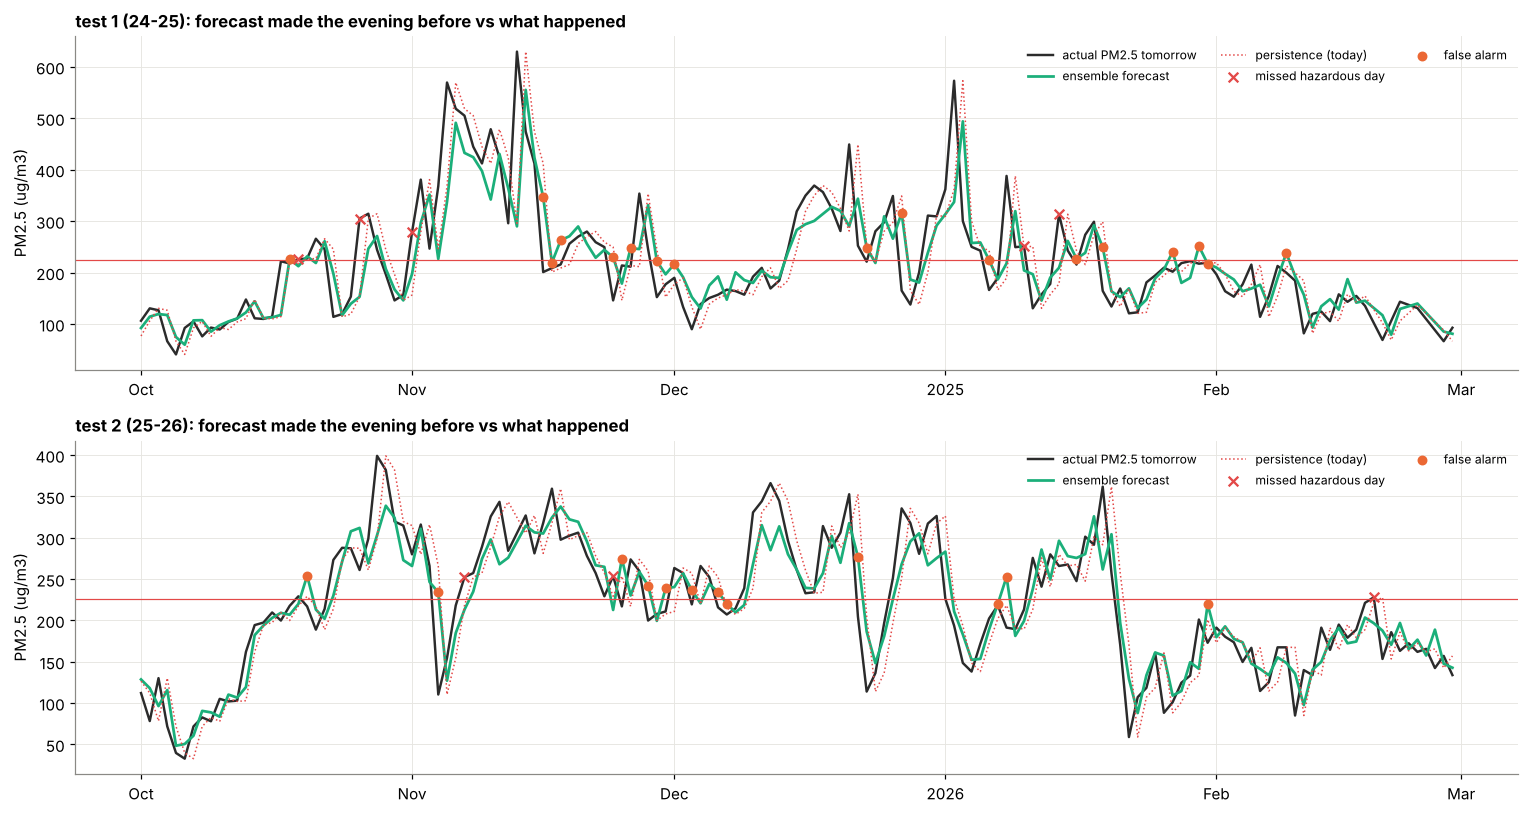

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5))
for ax, tname in zip(axes, TESTS):
    te = TESTS[tname][1]
    p = test_pred[tname]["Ensemble (selected)"]
    ax.plot(te.index, te["pm25_tomorrow"], color=DARK, lw=1.6, label="actual PM2.5 tomorrow")
    ax.plot(te.index, p, color=AQUA, lw=1.8, label="ensemble forecast")
    ax.plot(te.index, te["pm25_today"], color=RED, lw=1, ls=":", label="persistence (today)")
    ax.axhline(HAZARDOUS, color=RED, lw=0.8)
    miss = (te["pm25_tomorrow"] >= HAZARDOUS) & (p < TAU)
    false = (te["pm25_tomorrow"] < HAZARDOUS) & (p >= TAU)
    ax.scatter(te.index[miss], te["pm25_tomorrow"][miss], color=RED, s=40, marker="x", zorder=5, label="missed hazardous day")
    ax.scatter(te.index[false], p[false.to_numpy()], color=ORANGE, s=30, marker="o", zorder=5, label="false alarm")
    ax.set(title=f"{tname}: forecast made the evening before vs what happened", ylabel="PM2.5 (ug/m3)")
    ax.legend(loc="upper right", ncol=3, fontsize=8); nice_dates(ax)
fig.tight_layout(); savefig(fig, "p2_08_forecast_vs_actual")

**Discussion:**
- The forecast (green) follows the actual series (black) closely through both winters, including the big **November peaks**.
- Unlike persistence (red dotted), the ensemble starts to rise or fall **on the same day** as reality instead of one day late, especially when rain or wind is forecast.
- Most **missed hazardous days** (red ×) lie just above the line or at the very start of a sudden episode. **False alarms** (orange) are mostly days that ended just below 225.5. These are errors of degree, not of direction.

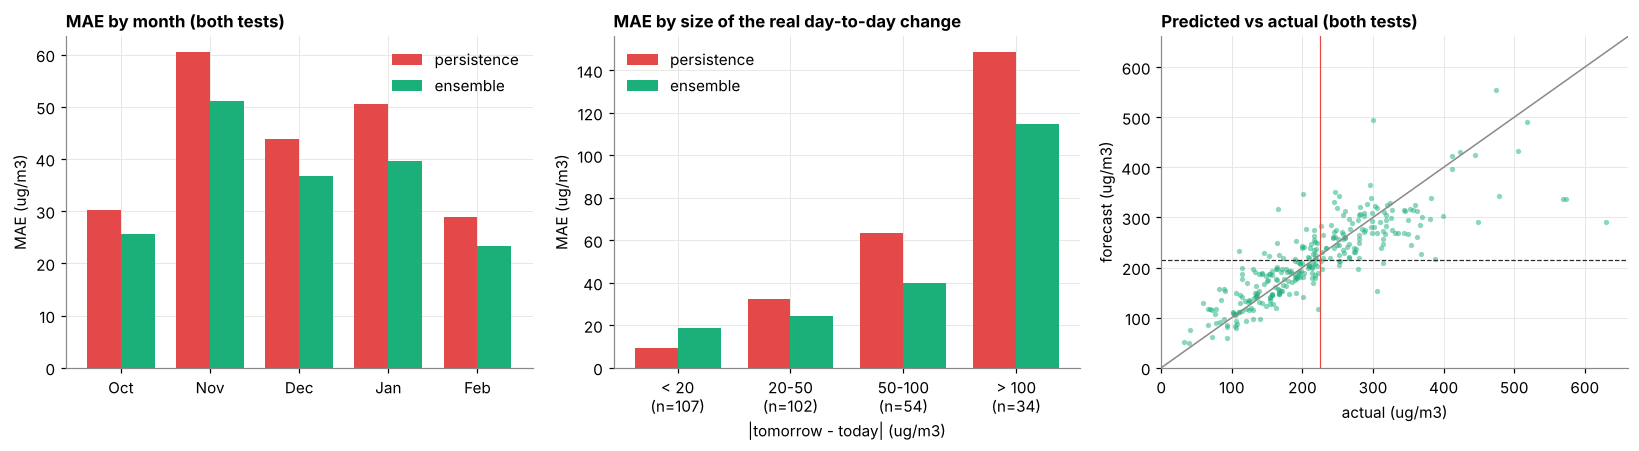

Biggest misses of the ensemble on the test winters:


,test,pm25_today,pm25_tomorrow,pred,rain_tomorrow,wind_speed_tomorrow,boundary_layer_tomorrow
date,,,,,,,
2024-11-13,test 1 (24-25),296.000,629.800,290.000,0.100,1.600,289.600
2025-01-02,test 1 (24-25),362.000,573.100,337.200,0.000,1.000,96.200
2024-11-05,test 1 (24-25),367.900,569.600,337.800,0.000,0.800,355.800
2025-01-03,test 1 (24-25),573.100,300.200,494.100,0.000,3.500,109.400
2025-01-08,test 1 (24-25),189.500,388.000,218.000,0.000,4.100,138.300
2024-12-21,test 1 (24-25),280.900,449.200,290.300,0.000,3.500,265.400


In [22]:
eval_df = pd.concat([TESTS[t][1].assign(pred=test_pred[t]["Ensemble (selected)"], test=t) for t in TESTS])
eval_df["abs_err_model"] = (eval_df["pm25_tomorrow"] - eval_df["pred"]).abs()
eval_df["abs_err_persist"] = (eval_df["pm25_tomorrow"] - eval_df["pm25_today"]).abs()
eval_df["change"] = eval_df["pm25_tomorrow"] - eval_df["pm25_today"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
mon = eval_df.groupby(eval_df.index.month)[["abs_err_persist", "abs_err_model"]].mean().reindex([10, 11, 12, 1, 2])
x = np.arange(len(mon)); w = 0.38
axes[0].bar(x - w / 2, mon["abs_err_persist"], w, color=RED, label="persistence")
axes[0].bar(x + w / 2, mon["abs_err_model"], w, color=AQUA, label="ensemble")
axes[0].set_xticks(x, ["Oct", "Nov", "Dec", "Jan", "Feb"]); axes[0].legend(loc="upper right")
axes[0].set(title="MAE by month (both tests)", ylabel="MAE (ug/m3)")

bins = pd.cut(eval_df["change"].abs(), [0, 20, 50, 100, 1000], labels=["< 20", "20-50", "50-100", "> 100"], include_lowest=True)
g = eval_df.groupby(bins, observed=False)[["abs_err_persist", "abs_err_model"]].mean()
n = eval_df.groupby(bins, observed=False).size()
x = np.arange(len(g))
axes[1].bar(x - w / 2, g["abs_err_persist"], w, color=RED, label="persistence")
axes[1].bar(x + w / 2, g["abs_err_model"], w, color=AQUA, label="ensemble")
axes[1].set_xticks(x, [f"{i}\n(n={k})" for i, k in zip(g.index, n)])
axes[1].set(title="MAE by size of the real day-to-day change", xlabel="|tomorrow - today| (ug/m3)", ylabel="MAE (ug/m3)")
axes[1].legend(loc="upper left")

axes[2].scatter(eval_df["pm25_tomorrow"], eval_df["pred"], s=12, alpha=0.5, color=AQUA, linewidths=0)
lim = eval_df[["pm25_tomorrow", "pred"]].max().max() * 1.05
axes[2].plot([0, lim], [0, lim], color=GREY, lw=1)
axes[2].axhline(TAU, color=DARK, lw=0.8, ls="--"); axes[2].axvline(HAZARDOUS, color=RED, lw=0.8)
axes[2].set(title="Predicted vs actual (both tests)", xlabel="actual (ug/m3)", ylabel="forecast (ug/m3)", xlim=(0, lim), ylim=(0, lim))
fig.tight_layout(); savefig(fig, "p2_09_error_analysis")

print("Biggest misses of the ensemble on the test winters:")
display(eval_df.sort_values("abs_err_model", ascending=False)
        .head(6)[["test", "pm25_today", "pm25_tomorrow", "pred", "rain_tomorrow", "wind_speed_tomorrow", "boundary_layer_tomorrow"]].round(1))

**Discussion (where the model adds value, and where it fails):**
- **By month:** the ensemble beats persistence in every month of the smog season. The gain is largest in the volatile months (**January and November**, about 10 µg/m³), when weather systems come and go.
- **By size of change:** on **calm days** (change < 20 µg/m³), **persistence is better** (MAE about 10 vs 19). When nothing changes, any adjustment the model makes is an error. **The real gain comes on days with big swings**: for changes of 50–100 µg/m³ the error drops from about 64 to 40, and for changes above 100 from about 149 to 115. Persistence is badly wrong on these days because it does not know about the coming rain, wind or stagnation, and these are the days a forecast is for. This is the main reason to use a model at all.
- **Predicted vs actual:** the points follow the diagonal, but the **largest values are under-predicted** (the cloud bends below the line above about 400 µg/m³). This regression-to-the-mean effect is typical: extreme peaks are rare in training, and their exact height depends on local conditions the inputs do not see.
- **Biggest misses:** these are sudden jumps or drops of 150+ µg/m³ between two days. Often there is no rain or wind signal in the inputs, which suggests a local cause (an inversion, a fire plume or dust) that daily-average features cannot capture.

## 10.2 Which features does the model rely on? (permutation importance)
**Permutation importance:** shuffle one feature in the test data and measure how much the MAE gets worse. A large increase means the model depends on that feature. This is computed on test 1, for the selected ensemble.

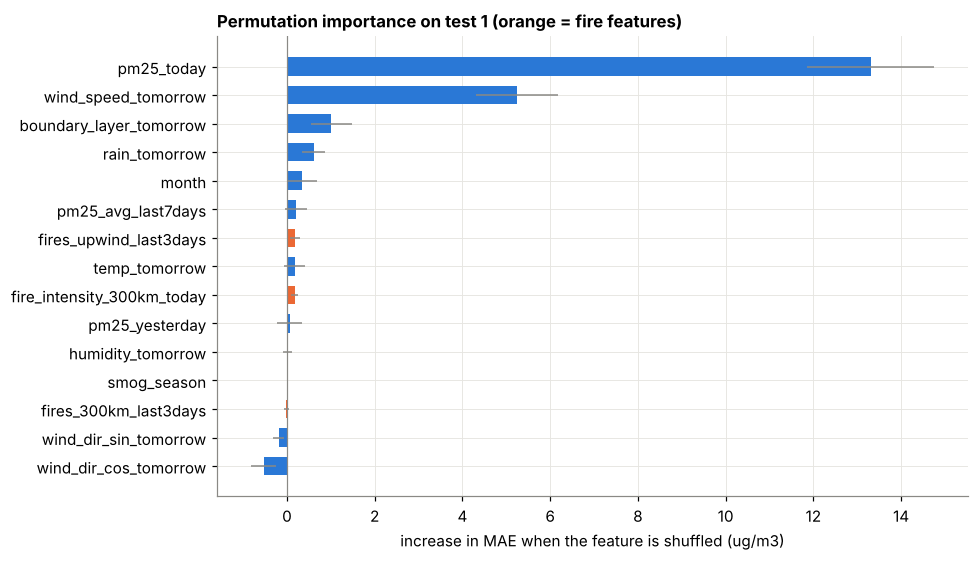

,pm25_today,wind_speed_tomorrow,boundary_layer_tomorrow,rain_tomorrow,month,pm25_avg_last7days,fires_upwind_last3days,temp_tomorrow,fire_intensity_300km_today,pm25_yesterday,humidity_tomorrow,smog_season,fires_300km_last3days,wind_dir_sin_tomorrow,wind_dir_cos_tomorrow
MAE increase,13.300,5.250,1.010,0.610,0.350,0.200,0.190,0.180,0.170,0.060,0.010,0.000,-0.020,-0.190,-0.530
std,1.440,0.940,0.470,0.260,0.330,0.250,0.110,0.240,0.090,0.290,0.110,0.000,0.060,0.120,0.290


In [23]:
ens_t1 = make_ensemble().fit(dev[FEATURES], dev["pm25_tomorrow"] - dev["pm25_today"])
pi = permutation_importance(ens_t1, test1[FEATURES], test1["pm25_tomorrow"] - test1["pm25_today"],
                            scoring="neg_mean_absolute_error", n_repeats=15, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"MAE increase": pi.importances_mean, "std": pi.importances_std}, index=FEATURES).sort_values("MAE increase")
fig, ax = plt.subplots(figsize=(9, 5.2))
cols = [ORANGE if f in FIRE_FEATURES else BLUE for f in imp.index]
ax.barh(imp.index, imp["MAE increase"], xerr=imp["std"], color=cols, height=0.65, error_kw={"ecolor": GREY, "lw": 1})
ax.axvline(0, color=GREY, lw=0.8)
ax.set(title="Permutation importance on test 1 (orange = fire features)", xlabel="increase in MAE when the feature is shuffled (ug/m3)")
fig.tight_layout(); savefig(fig, "p2_10_permutation_importance")
imp.sort_values("MAE increase", ascending=False).round(2).T

**Discussion:**
- **Today's PM2.5 is by far the most important input** (MAE +13 µg/m³ when shuffled). Because the model predicts the *change*, it uses today's level to judge how far the air can still get worse or how much it can clean up: very high days tend to come down.
- **Tomorrow's weather comes next**: **wind speed** (+5 µg/m³) is the strongest weather input, followed by **boundary-layer height** and **rain**, the same drivers found in the Phase-1 EDA.
- **Two fire features** (upwind fires and fire intensity) have **small positive importance** (about +0.2 µg/m³). The all-direction count adds nothing on top of them. Section 11 tests whether the fire effect is real.
- **Some features are near zero or slightly negative** in this winter: humidity, `smog_season`, and especially **wind direction** (−0.5). A negative value means the model did slightly *better* with the feature shuffled, so the direction pattern learned from earlier winters did not hold in 2024–25. This marks wind direction as a candidate for removal in future work. We keep the feature set fixed here, because it was chosen on training data in Phase 1, and changing it based on test results would be test-set leakage.

# 11. Research question: do crop-fire features help?
**Question:** does adding satellite crop-fire information improve the forecast beyond persistence and weather?

**Method: an ablation study.** We train the *same* ensemble (same settings) with four feature sets and compare them on the three validation winters and both test winters:
1. **No fire features** (12 features);
2. **Upwind fires only:** `fires_upwind_last3days`;
3. **All-direction fires only:** `fires_300km_last3days` and `fire_intensity_300km_today`;
4. **All fire features** (the selected model).

Because the differences can be small, we also compute a **95 % confidence interval** for the MAE difference on the test winters. We use a **block bootstrap**: the test days are resampled in 7-day blocks, which keeps the day-to-day autocorrelation intact.

In [24]:
VARIANTS = {"no fire features": NO_FIRE,
            "upwind fires only": NO_FIRE + ["fires_upwind_last3days"],
            "all-direction fires only": NO_FIRE + ["fires_300km_last3days", "fire_intensity_300km_today"],
            "all fire features (selected)": FEATURES}
t0 = time.time()
abl_rows, abl_pred = [], {}
for vname, feats in VARIANTS.items():
    y, p, d = walk_forward(make_ensemble, features=feats)
    row = {"features": vname, "n features": len(feats), **wf_mae(y, p, d)}
    for tname, (tr, te) in TESTS.items():
        pt = fit_predict(make_ensemble(), tr, te, feats)
        abl_pred[(vname, tname)] = pt
        row[f"MAE {tname}"] = mean_absolute_error(te["pm25_tomorrow"], pt)
        on = te.index.month.isin([10, 11])
        row[f"MAE Oct-Nov {tname}"] = mean_absolute_error(te["pm25_tomorrow"][on], pt[on])
    abl_rows.append(row)
ablation = pd.DataFrame(abl_rows).set_index("features")
ablation.to_csv(RESULTS_DIR / "fire_ablation.csv")
print(f"({time.time() - t0:.0f} s)")
ablation.round(2)

(15 s)


,n features,WF 2020-21,WF 2021-22,WF 2023-24,WF mean,MAE test 1 (24-25),MAE Oct-Nov test 1 (24-25),MAE test 2 (25-26),MAE Oct-Nov test 2 (25-26)
features,,,,,,,,,
no fire features,12,45.080,43.070,40.310,42.820,44.620,49.870,27.740,28.870
upwind fires only,13,45.150,42.980,40.210,42.780,44.490,49.690,26.690,26.620
all-direction fires only,14,45.110,43.110,40.210,42.810,44.330,49.370,27.090,27.190
all fire features (selected),15,44.990,43.240,40.280,42.840,44.320,49.330,26.940,26.540


In [25]:
def block_bootstrap_diff(y, p_without, p_with, block=7, n_boot=2000, seed=SEED):
    "95 % CI of MAE(without) - MAE(with), resampling days in blocks."
    rng = np.random.default_rng(seed)
    e = np.abs(y - p_without) - np.abs(y - p_with)
    n = len(e); starts = np.arange(0, n - block + 1)
    diffs = [np.mean(np.concatenate([e[s:s + block] for s in rng.choice(starts, size=int(np.ceil(n / block)))])[:n])
             for _ in range(n_boot)]
    return e.mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)

ci_rows = []
for tname, (tr, te) in TESTS.items():
    y = te["pm25_tomorrow"].to_numpy()
    for label, mask in [("whole winter", np.ones(len(te), bool)), ("Oct-Nov (burning season)", te.index.month.isin([10, 11]))]:
        m, lo, hi = block_bootstrap_diff(y[mask], abl_pred[("no fire features", tname)][mask],
                                         abl_pred[("all fire features (selected)", tname)][mask])
        ci_rows.append({"test": tname, "period": label, "MAE gain from fires": m, "95% CI low": lo, "95% CI high": hi,
                        "significant (CI above 0)": lo > 0})
fire_ci = pd.DataFrame(ci_rows).set_index(["test", "period"])
fire_ci.round(2)

MAE gain from fires  95% CI low  95% CI high  significant (CI above 0)
test           period                                                                                          
test 1 (24-25) whole winter                            0.300      -0.310        1.030                     False
               Oct-Nov (burning season)                0.540      -0.370        1.170                     False
test 2 (25-26) whole winter                            0.800      -0.160        1.830                     False
               Oct-Nov (burning season)                2.330       0.890        4.180                      True

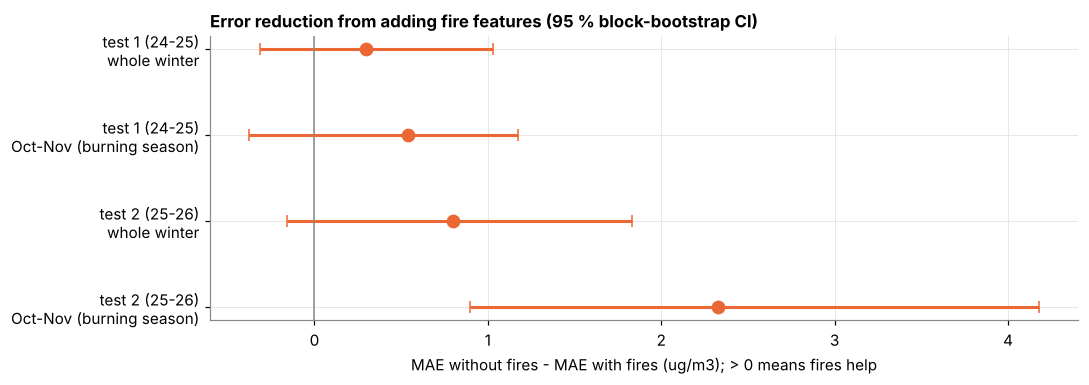

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.6))
labels = [f"{t}\n{p}" for t, p in fire_ci.index]
yv = np.arange(len(fire_ci))[::-1]
ax.errorbar(fire_ci["MAE gain from fires"], yv, xerr=[fire_ci["MAE gain from fires"] - fire_ci["95% CI low"],
            fire_ci["95% CI high"] - fire_ci["MAE gain from fires"]], fmt="o", color=ORANGE, ecolor=ORANGE, capsize=4, ms=8, lw=2)
ax.axvline(0, color=GREY, lw=1)
ax.set_yticks(yv, labels)
ax.set(title="Error reduction from adding fire features (95 % block-bootstrap CI)",
       xlabel="MAE without fires - MAE with fires (ug/m3); > 0 means fires help")
fig.tight_layout(); savefig(fig, "p2_11_fire_ablation")

**Answer to the research question:**
- **On the validation winters (2020–24), fire features make no difference**: about 42.8 µg/m³ with or without them.
- **On the test winters they help, but only clearly in one case.** Over the whole winter the gain is small (0.3 µg/m³ in test 1, 0.8 in test 2), and both confidence intervals include 0. **In the October–November burning season of 2025, however, the fire features reduce the error by 2.3 µg/m³ (95 % CI 0.9 to 4.2)**, about 8 % of that period's error. This is the only *statistically significant* effect.
- **A plausible reason it shows up in 2025:** Phase 1 found that in 2025, **two-thirds of the fires near Lahore were on the Pakistani side**, close to the city, while earlier years were dominated by more distant Indian fires. Nearby fires should have a more direct, next-day effect on Lahore's air. This is a hypothesis, not a proven cause.
- **Upwind vs all-direction fires:** the upwind-only model does almost as well as the full set in Oct–Nov 2025 (26.6 vs 26.5 µg/m³), and better than all-direction fires alone (27.2). There is a slight hint that direction matters, but the differences are too small to be sure, consistent with the Phase-1 EDA.
- **Honest conclusion:** **weather and persistence explain most of tomorrow's PM2.5. Satellite fire counts add a modest extra signal in the burning season, measurable in the most recent winter but not in earlier ones.**
- **Why the effect is not bigger:** (1) the fire season overlaps with stagnant weather, so part of the fire signal is already explained by the weather features; (2) satellite counts miss fires under smoke or cloud and burning between overpasses; (3) smoke can travel for several days, so its timing is blurred.
- **Practical decision:** keep the fire features in the final model. They **never made the forecast worse**, they gave the only significant improvement in the most recent burning season, and they cost nothing to compute from the free NASA API.

# 12. Final model and complete ML pipeline
## 12.1 Final model selection
| Choice | Decision | Evidence |
|---|---|---|
| Model | **Ensemble** (average of tuned Ridge, Random Forest and tuned Histogram Gradient Boosting) | Best validation MAE among change-target models (Section 7); lowest MAE on both test winters (Section 9) |
| Target | **Change** from today (then add today back) | Better on the most polluted days and able to forecast new records (Section 5); confirmed in test 1 (Section 9) |
| Features | **All 15 selected features**, including fires | No loss on validation; significant gain in the 2025 burning season (Section 11) |
| Warning | Warn if the forecast is ≥ **τ** (chosen on validation for recall ≥ 85 %) | Beats a dedicated classifier and persistence (Sections 8–9) |
| AQI category | EPA breakpoints applied to the forecast | Beats a direct multi-class classifier (Sections 8–9) |

## 12.2 The pipeline
The complete pipeline is one scikit-learn object:

```
input row (15 features)  ─►  ColumnTransformer (selects the 15 features in a fixed order)
                         ─►  VotingRegressor ─┬─ StandardScaler → Ridge
                                              ├─ RandomForestRegressor
                                              └─ HistGradientBoostingRegressor
                         ─►  predicted change  ─►  + today's PM2.5  ─►  PM2.5 forecast
                                                                   ─►  AQI category (EPA breakpoints)
                                                                   ─►  hazardous warning (forecast ≥ τ)
```

For deployment we **refit it on all 1,910 rows** (May 2019 – Oct 2026), so that it learns from the most recent winters, and save it with `joblib` together with a small JSON file of settings.

In [27]:
final_pipeline = Pipeline([
    ("select", ColumnTransformer([("features", "passthrough", FEATURES)], remainder="drop")),
    ("ensemble", make_ensemble()),
])
t0 = time.time()
final_pipeline.fit(df, df["pm25_tomorrow"] - df["pm25_today"])

MODEL_PATH = MODEL_DIR / "smog_forecaster.joblib"
CONFIG_PATH = MODEL_DIR / "smog_forecaster_config.json"
joblib.dump(final_pipeline, MODEL_PATH)
config = {
    "features": FEATURES, "target": "change (pm25_tomorrow - pm25_today)", "warning_threshold_ug_m3": TAU,
    "hazardous_level_ug_m3": HAZARDOUS, "category_bins": [b if np.isfinite(b) else None for b in CAT_BINS],
    "category_labels": CAT_LABELS, "trained_on": f"{df.index.min().date()} to {df.index.max().date()} ({len(df)} rows)",
    "scikit_learn_version": sklearn.__version__,
    "test_mae": {t: round(float(results.loc[(t, "Ensemble (selected)"), "MAE"]), 2) for t in TESTS},
    "hyperparameters": {name: {k: v for k, v in BEST[name].get_params().items() if k in searches[name][1]}
                        for name in BEST},
}
json.dump(config, open(CONFIG_PATH, "w"), indent=2, default=str)
print(f"Final pipeline trained in {time.time() - t0:.0f} s and saved:")
print(f"  {os.path.relpath(MODEL_PATH)}  ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")
print(f"  {os.path.relpath(CONFIG_PATH)}")
final_pipeline

Final pipeline trained in 1 s and saved:
  models/smog_forecaster.joblib  (14.8 MB)
  models/smog_forecaster_config.json


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('ensemble', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['split','sensor_type_tomorrow','pm25_today',...,'pm25_tomorrow', 'aqi_category_tomorrow','hazardous_tomorrow']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('features', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thr

## 12.3 Using the pipeline: the `forecast()` function
This is the function the live demo will call. It takes one or more rows of the 15 features (built each evening from the OpenAQ, NASA FIRMS and Open-Meteo **forecast** APIs) and returns the three answers. We **reload the model from disk** first, to prove that the saved file works on its own.

In [28]:
def forecast(inputs, model_path=MODEL_PATH, config_path=CONFIG_PATH):
    "Inputs: DataFrame with the 15 feature columns. Returns PM2.5 forecast, AQI category and hazardous warning."
    model = joblib.load(model_path)
    cfg = json.load(open(config_path))
    X = pd.DataFrame(inputs)
    missing = [f for f in cfg["features"] if f not in X.columns]
    if missing:
        raise ValueError(f"Missing input features: {missing}")
    pm = np.clip(model.predict(X) + X["pm25_today"].to_numpy(), 0, None)
    bins = [-np.inf if b is None and i == 0 else (np.inf if b is None else b) for i, b in enumerate(cfg["category_bins"])]
    cat = pd.cut(pm, bins, labels=cfg["category_labels"])
    return pd.DataFrame({"pm25_forecast": pm.round(1), "aqi_category": cat,
                         "hazardous_warning": pm >= cfg["warning_threshold_ug_m3"]}, index=X.index)

# check: the reloaded model gives exactly the same predictions as the one in memory
check = forecast(df.tail(30))
assert np.allclose(check["pm25_forecast"], np.clip(final_pipeline.predict(df.tail(30)) + df.tail(30)["pm25_today"], 0, None).round(1))
print("Reloaded model reproduces the in-memory predictions exactly.")

demo = df.loc["2025-11-01":"2025-11-10"]
out = forecast(demo).join(demo[["pm25_today", "pm25_tomorrow"]])
print("Demo - forecasts for 1-10 Nov 2025 (note: the final model has seen these days in training, so this only shows the output format):")
out

Reloaded model reproduces the in-memory predictions exactly.
Demo - forecasts for 1-10 Nov 2025 (note: the final model has seen these days in training, so this only shows the output format):


,pm25_forecast,aqi_category,hazardous_warning,pm25_today,pm25_tomorrow
date,,,,,
2025-11-01,271.400,Hazardous,True,314.811,279.964
2025-11-02,309.500,Hazardous,True,279.964,316.034
2025-11-03,251.000,Hazardous,True,316.034,265.902
2025-11-04,214.700,Very Unhealthy,False,265.902,110.374
2025-11-05,134.200,Very Unhealthy,False,110.374,154.636
2025-11-06,190.100,Very Unhealthy,False,154.636,218.217
2025-11-07,225.200,Very Unhealthy,True,218.217,252.453
2025-11-08,242.400,Hazardous,True,252.453,257.343
2025-11-09,274.200,Hazardous,True,257.343,289.134


In [29]:
# A hypothetical evening, typed in by hand (what the live demo will do with API data):
# a smoggy November day with 260 ug/m3 today, a shallow boundary layer, calm wind, no rain and many fires
evening = pd.DataFrame([{
    "pm25_today": 260, "pm25_yesterday": 230, "pm25_avg_last7days": 210,
    "boundary_layer_tomorrow": 250, "temp_tomorrow": 17, "humidity_tomorrow": 70, "wind_speed_tomorrow": 3.0,
    "rain_tomorrow": 0.0, "wind_dir_sin_tomorrow": np.sin(np.radians(300)), "wind_dir_cos_tomorrow": np.cos(np.radians(300)),
    "fires_upwind_last3days": 600, "fires_300km_last3days": 1500, "fire_intensity_300km_today": 4000,
    "month": 11, "smog_season": 1}])
rainy = evening.assign(rain_tomorrow=12.0, wind_speed_tomorrow=12.0, boundary_layer_tomorrow=700)
print("Same evening, two different weather forecasts for tomorrow:")
pd.concat([forecast(evening).assign(scenario="calm, dry, many fires"),
           forecast(rainy).assign(scenario="rain + strong wind forecast")]).set_index("scenario")

Same evening, two different weather forecasts for tomorrow:


,pm25_forecast,aqi_category,hazardous_warning
scenario,,,
"calm, dry, many fires",287.600,Hazardous,True
rain + strong wind forecast,187.100,Very Unhealthy,False


**Discussion:** the pipeline behaves sensibly.
- With a **calm, dry forecast** and many fires, it predicts that the smog stays **Hazardous** and raises a warning. If the **weather forecast changes to rain and strong wind**, the same evening's forecast drops by about 100 µg/m³ and no warning is issued.
- In the November 2025 demo table, 7 Nov shows a **warning together with the category "Very Unhealthy"** (forecast 225, just below 225.5). This is intended: the warning threshold (215) is deliberately lower than the hazardous line, so the warning means *"likely to become hazardous"*.

This is exactly the behaviour persistence cannot provide, and it shows the forecast responds to the physical drivers rather than just copying today.

**For the live demo**, the 15 inputs are filled each evening from:
- **OpenAQ**: today's, yesterday's and the last 7 days' PM2.5;
- the **Open-Meteo forecast API**: tomorrow's weather, instead of ERA5;
- **NASA FIRMS near-real-time**: fires in the last 3 days.

Then `forecast()` gives the answer in under a second.

# 13. Conclusions

In [30]:
summary = pd.DataFrame({
    tname: {"Persistence MAE": results.loc[(tname, "Persistence"), "MAE"],
            "Final model MAE": results.loc[(tname, "Ensemble (selected)"), "MAE"],
            "Improvement %": results.loc[(tname, "Ensemble (selected)"), "MAE vs persistence %"],
            "Final model R2": results.loc[(tname, "Ensemble (selected)"), "R2"],
            "Warning recall": results.loc[(tname, "Ensemble (selected)"), "warn recall"],
            "Warning precision": results.loc[(tname, "Ensemble (selected)"), "warn precision"],
            "AQI accuracy (persistence)": results.loc[(tname, "Persistence"), "AQI accuracy"],
            "AQI accuracy (final model)": results.loc[(tname, "Ensemble (selected)"), "AQI accuracy"],
            "AQI within one category": results.loc[(tname, "Ensemble (selected)"), "AQI within one category"]}
    for tname in TESTS})
summary.to_csv(RESULTS_DIR / "final_summary.csv")
summary.round(3)

,test 1 (24-25),test 2 (25-26)
Persistence MAE,52.465,33.838
Final model MAE,44.321,26.937
Improvement %,15.523,20.394
Final model R2,0.636,0.810
Warning recall,0.909,0.955
Warning precision,0.746,0.842
AQI accuracy (persistence),0.735,0.747
AQI accuracy (final model),0.769,0.820
AQI within one category,1.000,0.993


### What we achieved
1. **A complete, reproducible ML pipeline**, from raw API data (Phase 1) to a saved forecasting model with a `forecast()` function (Phase 2), all built on data we collected ourselves.
2. **Task 1, PM2.5 regression:** the final ensemble beats the persistence baseline by **15.5 % and 20.4 % MAE** on two unseen smog winters (44.3 and 26.9 µg/m³). The gain is biggest on days with large changes, where a forecast is most useful.
3. **Task 3, hazardous warning:** with a threshold chosen on validation data (τ = 215), the warning catches **91 % and 96 % of hazardous days** on the test winters (persistence: 80–85 %), with 75–84 % precision.
4. **Task 2, AQI category:** the category is correct on 77–82 % of test days (persistence: 73–75 %), and on 99–100 % it is within one category. It is better than a dedicated classifier.
5. **Research question:** satellite crop-fire features gave **no gain on the earlier validation winters**, but a **significant gain in the 2025 burning season** (−2.3 µg/m³). **Weather and persistence explain most** of tomorrow's smog.

### Methodological points worth noting
- **No leakage:** time-based splits only; tuning used only the training period; the test winters were used once at the end.
- **Robust model choice:** walk-forward validation over three winters, because one winter alone gave unstable rankings.
- **A model for all three tasks:** the regression forecast outperformed the dedicated classifiers, which keeps the system simple.

### Limitations
- **Weather inputs:** training used ERA5 reanalysis for "tomorrow's weather". A real forecast has errors, so live accuracy will be somewhat lower than the test scores.
- **Extreme peaks** (above about 400 µg/m³) are under-predicted, because they are rare in training.
- **Small data:** about 1,900 rows, and the 2021–23 winters have gaps (US-monitor outages). More winters will improve the model.
- **Test 2** depends on the calibration of low-cost sensors (Phase 1); calibration error is part of its "truth".

### Future work
- Use **archived weather forecasts** (Open-Meteo Previous Runs API) instead of reanalysis to train on realistic inputs.
- Add **multi-day lead times** (t+2, t+3) and **prediction intervals** (quantile gradient boosting).
- Add smoke-transport features (back-trajectories), and more sensors across Punjab.

### References
- Pedregosa et al. (2011), *Scikit-learn: Machine Learning in Python*, JMLR 12.
- Breiman (2001), *Random Forests*, Machine Learning 45; Friedman (2001), *Greedy function approximation: a gradient boosting machine*, Annals of Statistics.
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed.): time-series cross-validation and persistence benchmarks.
- US EPA (2024), PM2.5 AQI breakpoints. Data: NASA FIRMS, OpenAQ, Open-Meteo/ERA5 (see Phase 1).